# RT-DETRv2 for F1/10th

[RT-DETRv2](https://arxiv.org/abs/2407.17140) is a real-time DETR detector: a CNN backbone, a hybrid
encoder and a transformer decoder that outputs a fixed set of 300 detections, trained with one-to-one
(Hungarian) matching, so there is no NMS and no anchor boxes to design.

Steps to follow:
1. **Read** the architecture (section 2) and **run** the pretrained detector (section 3).
2. **Load** the F1/10th car dataset. The new class `f1tenth_car` is **added to COCO's 80** classes
3. **Fine-tune** with the repo's loss (section 6). Given F1/10th dataset only labels the car
4. **Infer** with the fine-tuned model (section 8).

**Dataset format** (`lab-7/f110_dataset_20220209`):
```
f110_dataset_20220209/
  0.jpg 1.jpg ... 1791.jpg     # 640x360 RGB
  labels.npy                   # float (N, 4); row i = (cx, cy, w, h) of the car in i.jpg, in pixels
```

## 0. Install

In [ ]:
# @title 0. Install (provided)

# Run once per environment (Colab / fresh venv). torch and torchvision (>= 0.17) come with Colab.
# scipy: Hungarian matcher; torchmetrics + pycocotools: COCO mAP.
%pip install -q "torchmetrics[detection]" pycocotools scipy pyyaml pillow matplotlib

In [ ]:
# @title 0. Install (provided)

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# @title 0. Install (provided)
# change to your project folder if required
%cd /content/drive/MyDrive/ESE6150/Perception_Lab


/content/drive/MyDrive/ESE6150/Perception_Lab


## 1. Configuration

In [ ]:
# @title
import math
from collections import Counter
import os
import random
import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader, Dataset

# paths -- edit these
WS = os.getcwd()
print(WS)
DATA_FORMAT = "f110_npy"
F110_DIR = WS + "/f110_yolo_2022/f110_dataset_20220209"
CLASS_NAMES = ["f1tenth_car"]
OUT_DIR = WS + "/f1tenth_perception/" + "runs" + "/rtdetrv2_f1tenth"


@dataclass
class TrainConfig:
    checkpoint: str = "https://github.com/lyuwenyu/storage/releases/download/v0.2/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth"
    image_size: int = 640                       # square network input (the repo's Resize [640, 640])
    ### STUDENT CODE HERE ###
    epochs: int = 20
    batch_size: int = 8
    lr: float = 1e-4
    weight_decay: float = 1e-4
    betas: tuple = (0.9, 0.999)
    warmup_steps: int = 200                    # LinearWarmup, in iterations
    lr_milestones: list = field(default_factory=lambda: [1000])   # MultiStepLR, in epochs (i.e. constant lr)
    clip_max_norm: float = 0.1
    ema_decay: float = 0.9999
    ema_warmups: int = 2000
    no_aug_epochs: int = 3
    freeze_backbone: bool = False               # True for very small datasets (< ~100 images)
    keep_coco_classes: bool = True              # 80 COCO classes + CLASS_NAMES (False: CLASS_NAMES only)
    ### END CODE HERE ###
    pseudo_labels: bool = True                  # COCO model labels the other objects (keeps COCO alive)
    pseudo_label_threshold: float = 0.5         # its detections above this score become labels
    init_new_class_from: str | None = None      # e.g. "car": new class starts as a copy of a COCO class
    val_fraction: float = 0.15
    split_block: int = 50                       # consecutive frames kept together in one split
    num_workers: int = 2
    eval_every: int = 1
    seed: int = 0
    out_dir: Path = OUT_DIR


cfg = TrainConfig()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

/content/drive/MyDrive/ESE6150/Perception_Lab
device: cuda | torch 2.11.0+cu130


## 2. RT-DETRv2-S, from the repo

The model is `RTDETR(backbone, encoder, decoder)`. Shapes are for one 640 x 640 image:

```
image (3, 640, 640), values in [0, 1]
 │
 ├─ backbone: PResNet (depth 18, variant d) ...........................
 │     C3 (128, 80, 80)   C4 (256, 40, 40)   C5 (512, 20, 20)       strides 8, 16, 32
 │
 ├─ encoder: HybridEncoder ............................................
 │     input_proj
 │     AIFI
 │     CCFF
 │
 └─ decoder: RTDETRTransformerv2 ......................................
       input_proj + flatten all levels
       query selection (Section 2.6)
       TransformerDecoder (3 x TransformerDecoderLayer) -> pred_logits (300, num_classes), pred_boxes (300, 4) as (cx, cy, w, h) in [0, 1]
```


### 2.1 Helpers
`inverse_sigmoid` is how boxes are
refined in logit space; `bias_init_with_prob(0.01)` starts every class head at probability 0.01.

In [ ]:
import copy
import functools
import math
from collections import OrderedDict
from pathlib import Path
from typing import Dict, List

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init
import torchvision
from scipy.optimize import linear_sum_assignment
from torch import Tensor
from torchvision.ops.boxes import box_area


def inverse_sigmoid(x: torch.Tensor, eps: float=1e-5) -> torch.Tensor:
    x = x.clip(min=0., max=1.)
    return torch.log(x.clip(min=eps) / (1 - x).clip(min=eps))


def bias_init_with_prob(prior_prob=0.01):
    """initialize conv/fc bias value according to a given probability value."""
    bias_init = float(-math.log((1 - prior_prob) / prior_prob))
    return bias_init


def get_activation(act: str, inpace: bool=True):
  ### STUDENT CODE HERE ###
    """get activation
    """
    if act is None:
        return nn.Identity()

    elif isinstance(act, nn.Module):
        return act

    act = act.lower()

    if act == 'silu' or act == 'swish':
        m = ....

    elif act == 'relu':
        m = ...

    elif act == 'leaky_relu':
        m = ...

    elif act == 'silu':
        m = ...

    elif act == 'gelu':
        m = ...

    elif act == 'hardsigmoid':
        m = ...

    else:
        raise RuntimeError('')

    if hasattr(m, 'inplace'):
        m.inplace = inpace
  ### END CODE HERE ###
    return m


def box_cxcywh_to_xyxy(x: Tensor) -> Tensor:
    # b = [x1, y1, x2, y2]
    # x1 = center - w/2
    ### STUDENT CODE HERE ###
    x_c, y_c, w, h = x.unbind(-1)
    b = []
    return torch.stack(b, dim=-1)
    ### END CODE HERE ###

def box_xyxy_to_cxcywh(x: Tensor) -> Tensor:
    # b = [x1, y1, x2, y2]
    # x1 = center - w/2
    ### STUDENT CODE HERE ###
    x0, y0, x1, y1 = x.unbind(-1)
    b = []
    ### END CODE HERE ###
    return torch.stack(b, dim=-1)


def box_iou(boxes1: Tensor, boxes2: Tensor):
    ### STUDENT CODE HERE ###

    iou = inter / union
    ### END CODE HERE ###
    return iou, union


def generalized_box_iou(boxes1, boxes2):
    """
    Generalized IoU from https://giou.stanford.edu/

    The boxes should be in [x0, y0, x1, y1] format

    Returns a [N, M] pairwise matrix, where N = len(boxes1)
    and M = len(boxes2)
    """
    # degenerate boxes gives inf / nan results

    assert (boxes1[:, 2:] >= boxes1[:, :2]).all()
    assert (boxes2[:, 2:] >= boxes2[:, :2]).all()
    iou, union = box_iou(boxes1, boxes2)

    lt = torch.min(boxes1[:, None, :2], boxes2[:, :2])
    rb = torch.max(boxes1[:, None, 2:], boxes2[:, 2:])

    wh = (rb - lt).clamp(min=0)  # [N,M,2]
    area = wh[:, :, 0] * wh[:, :, 1]

    return iou - (area - union) / area

### 2.2 Backbone: `PResNet` (ResNet18-vd)
ResNet-18 with the "vd" tweaks of [He et al. 2019](https://arxiv.org/abs/1812.01187):
a stem of three 3x3 convs instead of one 7x7, and downsampling shortcuts that average-pool before
their 1x1 conv.
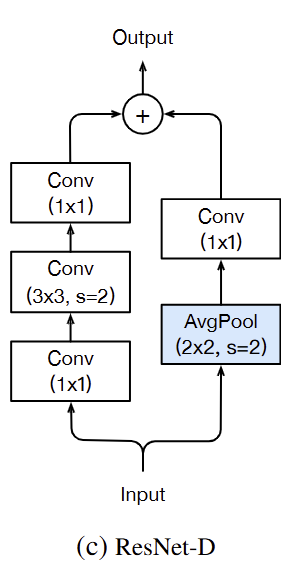

For r18 the config sets `freeze_norm=False`, so the
BatchNorm layers are normal (trainable) ones; `FrozenBatchNorm2d` is only used with `freeze_norm=True`.

In [ ]:
class FrozenBatchNorm2d(nn.Module):
    """
    BatchNorm2d where the batch statistics and the affine parameters are fixed.
    """
    def __init__(self, num_features, eps=1e-5):
        super(FrozenBatchNorm2d, self).__init__()
        n = num_features
        self.register_buffer("weight", torch.ones(n))
        self.register_buffer("bias", torch.zeros(n))
        self.register_buffer("running_mean", torch.zeros(n))
        self.register_buffer("running_var", torch.ones(n))
        self.eps = eps
        self.num_features = n

    def _load_from_state_dict(self, state_dict, prefix, local_metadata, strict,
                              missing_keys, unexpected_keys, error_msgs):
        num_batches_tracked_key = prefix + 'num_batches_tracked'
        if num_batches_tracked_key in state_dict:
            del state_dict[num_batches_tracked_key]

        super(FrozenBatchNorm2d, self)._load_from_state_dict(
            state_dict, prefix, local_metadata, strict,
            missing_keys, unexpected_keys, error_msgs)

    def forward(self, x):
        # move reshapes to the beginning
        # to make it fuser-friendly
        w = self.weight.reshape(1, -1, 1, 1)
        b = self.bias.reshape(1, -1, 1, 1)
        rv = self.running_var.reshape(1, -1, 1, 1)
        rm = self.running_mean.reshape(1, -1, 1, 1)
        scale = w * (rv + self.eps).rsqrt()
        bias = b - rm * scale
        return x * scale + bias

    def extra_repr(self):
        return (
            "{num_features}, eps={eps}".format(**self.__dict__)
        )


ResNet_cfg = {
    18: [2, 2, 2, 2],
    34: [3, 4, 6, 3],
    50: [3, 4, 6, 3],
    101: [3, 4, 23, 3],
    # 152: [3, 8, 36, 3],
}


donwload_url = {
    18: 'https://github.com/lyuwenyu/storage/releases/download/v0.1/ResNet18_vd_pretrained_from_paddle.pth',
    34: 'https://github.com/lyuwenyu/storage/releases/download/v0.1/ResNet34_vd_pretrained_from_paddle.pth',
    50: 'https://github.com/lyuwenyu/storage/releases/download/v0.1/ResNet50_vd_ssld_v2_pretrained_from_paddle.pth',
    101: 'https://github.com/lyuwenyu/storage/releases/download/v0.1/ResNet101_vd_ssld_pretrained_from_paddle.pth',
}


class ConvNormLayer(nn.Module):
    def __init__(self, ch_in, ch_out, kernel_size, stride, padding=None, bias=False, act=None):
        super().__init__()
        ### STUDENT CODE HERE ###
        self.conv =
        self.norm =
        self.act =

    def forward(self, x):
        return
        ### END CODE HERE ###

class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, ch_in, ch_out, stride, shortcut, act='relu', variant='b'):
        super().__init__()

        self.shortcut = shortcut

        if not shortcut:
            if variant == 'd' and stride == 2:
                self.short = nn.Sequential(OrderedDict([
                    ('pool', nn.AvgPool2d(2, 2, 0, ceil_mode=True)),
                    ('conv', ConvNormLayer(ch_in, ch_out, 1, 1))
                ]))
            else:
                self.short = ConvNormLayer(ch_in, ch_out, 1, stride)

        self.branch2a = ConvNormLayer(ch_in, ch_out, 3, stride, act=act)
        self.branch2b = ConvNormLayer(ch_out, ch_out, 3, 1, act=None)
        self.act = nn.Identity() if act is None else get_activation(act)


    def forward(self, x):
        out = self.branch2a(x)
        out = self.branch2b(out)
        if self.shortcut:
            short = x
        else:
            short = self.short(x)

        out = out + short
        out = self.act(out)

        return out


class Blocks(nn.Module):
    def __init__(self, block, ch_in, ch_out, count, stage_num, act='relu', variant='b'):
        super().__init__()

        self.blocks = nn.ModuleList()
        for i in range(count):
            self.blocks.append(
                block(
                    ch_in,
                    ch_out,
                    stride=2 if i == 0 and stage_num != 2 else 1,
                    shortcut=False if i == 0 else True,
                    variant=variant,
                    act=act)
            )

            if i == 0:
                ch_in = ch_out * block.expansion

    def forward(self, x):
        out = x
        for block in self.blocks:
            out = block(out)
        return out


class PResNet(nn.Module):
    def __init__(
        self,
        depth,
        variant='d',
        num_stages=4,
        return_idx=[0, 1, 2, 3],
        act='relu',
        freeze_at=-1,
        freeze_norm=True,
        pretrained=False):
        super().__init__()

        block_nums = ResNet_cfg[depth]
        ch_in = 64
        if variant in ['c', 'd']:
            conv_def = [
                [3, ch_in // 2, 3, 2, "conv1_1"],
                [ch_in // 2, ch_in // 2, 3, 1, "conv1_2"],
                [ch_in // 2, ch_in, 3, 1, "conv1_3"],
            ]
        else:
            conv_def = [[3, ch_in, 7, 2, "conv1_1"]]

        self.conv1 = nn.Sequential(OrderedDict([
            (name, ConvNormLayer(cin, cout, k, s, act=act)) for cin, cout, k, s, name in conv_def
        ]))

        ch_out_list = [64, 128, 256, 512]
        block = BottleNeck if depth >= 50 else BasicBlock

        _out_channels = [block.expansion * v for v in ch_out_list]
        _out_strides = [4, 8, 16, 32]

        self.res_layers = nn.ModuleList()
        for i in range(num_stages):
            stage_num = i + 2
            self.res_layers.append(
                Blocks(block, ch_in, ch_out_list[i], block_nums[i], stage_num, act=act, variant=variant)
            )
            ch_in = _out_channels[i]

        self.return_idx = return_idx
        self.out_channels = [_out_channels[_i] for _i in return_idx]
        self.out_strides = [_out_strides[_i] for _i in return_idx]

        if freeze_at >= 0:
            self._freeze_parameters(self.conv1)
            for i in range(min(freeze_at, num_stages)):
                self._freeze_parameters(self.res_layers[i])

        if freeze_norm:
            self._freeze_norm(self)

        if pretrained:
            if isinstance(pretrained, bool) or 'http' in pretrained:
                state = torch.hub.load_state_dict_from_url(donwload_url[depth], map_location='cpu')
            else:
                state = torch.load(pretrained, map_location='cpu')
            self.load_state_dict(state)
            print(f'Load PResNet{depth} state_dict')

    def _freeze_parameters(self, m: nn.Module):
        for p in m.parameters():
            p.requires_grad = False

    def _freeze_norm(self, m: nn.Module):
        if isinstance(m, nn.BatchNorm2d):
            m = FrozenBatchNorm2d(m.num_features)
        else:
            for name, child in m.named_children():
                _child = self._freeze_norm(child)
                if _child is not child:
                    setattr(m, name, _child)
        return m

    def forward(self, x):
        conv1 = self.conv1(x)
        x = F.max_pool2d(conv1, kernel_size=3, stride=2, padding=1)
        outs = []
        for idx, stage in enumerate(self.res_layers):
            x = stage(x)
            if idx in self.return_idx:
                outs.append(x)
        return outs

### 2.3 Hybrid encoder: AIFI + CCFF

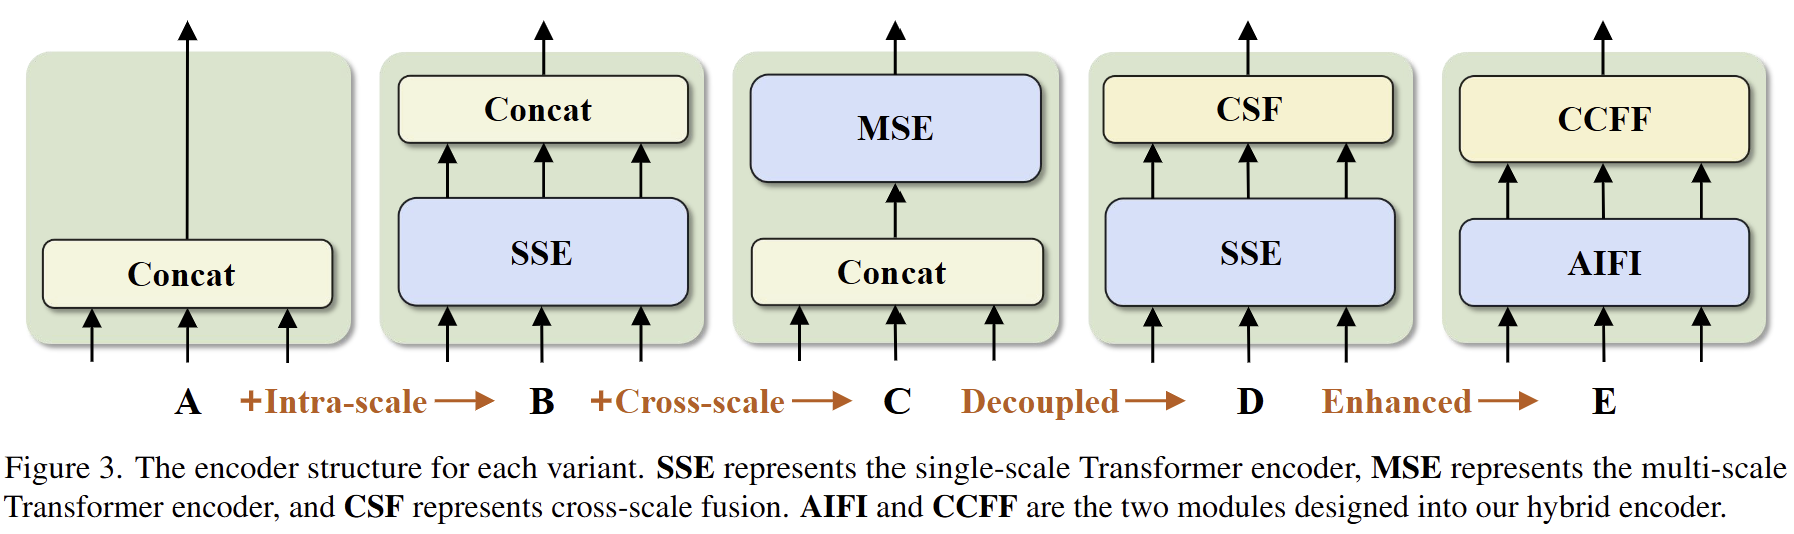

* **AIFI** (Attention-based Intra-scale Feature Interaction)

* **CCFF** (CNN-based Cross-scale Feature Fusion):
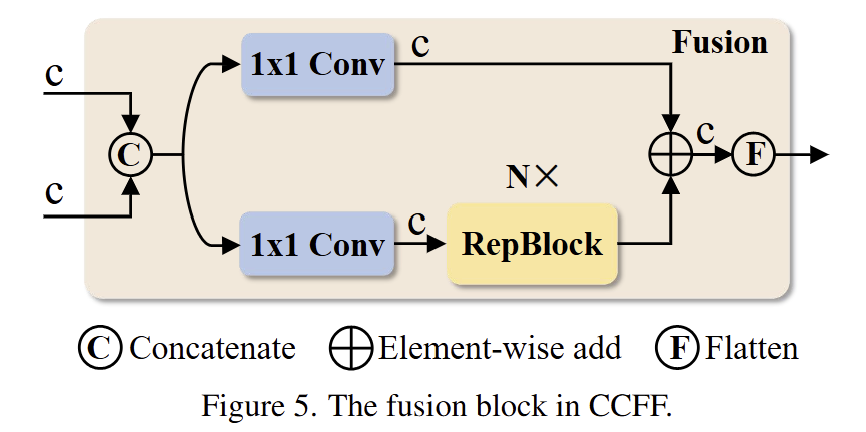
  

In [ ]:

class RepVggBlock(nn.Module):
    def __init__(self, ch_in, ch_out, act='relu'):
        super().__init__()
        self.ch_in = ch_in
        self.ch_out = ch_out
        self.conv1 = ConvNormLayer(ch_in, ch_out, 3, 1, padding=1, act=None)
        self.conv2 = ConvNormLayer(ch_in, ch_out, 1, 1, padding=0, act=None)
        self.act = nn.Identity() if act is None else get_activation(act)

    def forward(self, x):
        if hasattr(self, 'conv'):
            y = self.conv(x)
        else:
            y = self.conv1(x) + self.conv2(x)

        return self.act(y)

    def convert_to_deploy(self):
        if not hasattr(self, 'conv'):
            self.conv = nn.Conv2d(self.ch_in, self.ch_out, 3, 1, padding=1)

        kernel, bias = self.get_equivalent_kernel_bias()
        self.conv.weight.data = kernel
        self.conv.bias.data = bias

    def get_equivalent_kernel_bias(self):
        kernel3x3, bias3x3 = self._fuse_bn_tensor(self.conv1)
        kernel1x1, bias1x1 = self._fuse_bn_tensor(self.conv2)

        return kernel3x3 + self._pad_1x1_to_3x3_tensor(kernel1x1), bias3x3 + bias1x1

    def _pad_1x1_to_3x3_tensor(self, kernel1x1):
        if kernel1x1 is None:
            return 0
        else:
            return F.pad(kernel1x1, [1, 1, 1, 1])

    def _fuse_bn_tensor(self, branch: ConvNormLayer):
        if branch is None:
            return 0, 0
        kernel = branch.conv.weight
        running_mean = branch.norm.running_mean
        running_var = branch.norm.running_var
        gamma = branch.norm.weight
        beta = branch.norm.bias
        eps = branch.norm.eps
        std = (running_var + eps).sqrt()
        t = (gamma / std).reshape(-1, 1, 1, 1)
        return kernel * t, beta - running_mean * gamma / std


class CSPRepLayer(nn.Module):
    def __init__(self,
                 in_channels,
                 out_channels,
                 num_blocks=3,
                 expansion=1.0,
                 bias=None,
                 act="silu"):
        super(CSPRepLayer, self).__init__()
        hidden_channels = int(out_channels * expansion)
        self.conv1 = ConvNormLayer(in_channels, hidden_channels, 1, 1, bias=bias, act=act)
        self.conv2 = ConvNormLayer(in_channels, hidden_channels, 1, 1, bias=bias, act=act)
        self.bottlenecks = nn.Sequential(*[
            RepVggBlock(hidden_channels, hidden_channels, act=act) for _ in range(num_blocks)
        ])
        if hidden_channels != out_channels:
            self.conv3 = ConvNormLayer(hidden_channels, out_channels, 1, 1, bias=bias, act=act)
        else:
            self.conv3 = nn.Identity()

    def forward(self, x):
        x_1 = self.conv1(x)
        x_1 = self.bottlenecks(x_1)
        x_2 = self.conv2(x)
        return self.conv3(x_1 + x_2)


class TransformerEncoderLayer(nn.Module):
    def __init__(self,
                 d_model,
                 nhead,
                 dim_feedforward=2048,
                 dropout=0.1,
                 activation="relu",
                 normalize_before=False):
        super().__init__()
        ### STUDENT CODE HERE ###
        self.normalize_before = normalize_before

        self.self_attn =

        self.linear1 =
        self.dropout =
        self.linear2 =

        self.norm1 =
        self.norm2 =
        self.dropout1 =
        self.dropout2 =
        self.activation =
        ### END CODE HERE ###

    @staticmethod
    def with_pos_embed(tensor, pos_embed):
        return tensor if pos_embed is None else tensor + pos_embed

    def forward(self, src, src_mask=None, pos_embed=None) -> torch.Tensor:
        residual = src
        if self.normalize_before:
            src = self.norm1(src)
        q = k = self.with_pos_embed(src, pos_embed)
        src, _ = self.self_attn(q, k, value=src, attn_mask=src_mask, need_weights=False)

        src = residual + self.dropout1(src)
        if not self.normalize_before:
            src = self.norm1(src)

        residual = src
        if self.normalize_before:
            src = self.norm2(src)
        src = self.linear2(self.dropout(self.activation(self.linear1(src))))
        src = residual + self.dropout2(src)
        if not self.normalize_before:
            src = self.norm2(src)
        return src


class TransformerEncoder(nn.Module):
    def __init__(self, encoder_layer, num_layers, norm=None):
        super(TransformerEncoder, self).__init__()
        self.layers = nn.ModuleList([copy.deepcopy(encoder_layer) for _ in range(num_layers)])
        self.num_layers = num_layers
        self.norm = norm

    def forward(self, src, src_mask=None, pos_embed=None) -> torch.Tensor:
        output = src
        for layer in self.layers:
            output = layer(output, src_mask=src_mask, pos_embed=pos_embed)

        if self.norm is not None:
            output = self.norm(output)

        return output


class HybridEncoder(nn.Module):
    __share__ = ['eval_spatial_size', ]

    def __init__(self,
                 in_channels=[512, 1024, 2048],
                 feat_strides=[8, 16, 32],
                 hidden_dim=256,
                 nhead=8,
                 dim_feedforward = 1024,
                 dropout=0.0,
                 enc_act='gelu',
                 use_encoder_idx=[2],
                 num_encoder_layers=1,
                 pe_temperature=10000,
                 expansion=1.0,
                 depth_mult=1.0,
                 act='silu',
                 eval_spatial_size=None,
                 version='v2'):
        super().__init__()
        self.in_channels = in_channels
        self.feat_strides = feat_strides
        self.hidden_dim = hidden_dim
        self.use_encoder_idx = use_encoder_idx
        self.num_encoder_layers = num_encoder_layers
        self.pe_temperature = pe_temperature
        self.eval_spatial_size = eval_spatial_size
        self.out_channels = [hidden_dim for _ in range(len(in_channels))]
        self.out_strides = feat_strides

        # channel projection
        self.input_proj = nn.ModuleList()
        for in_channel in in_channels:
            if version == 'v1':
                proj = nn.Sequential(
                    nn.Conv2d(in_channel, hidden_dim, kernel_size=1, bias=False),
                    nn.BatchNorm2d(hidden_dim))
            elif version == 'v2':
                proj = nn.Sequential(OrderedDict([
                    ('conv', nn.Conv2d(in_channel, hidden_dim, kernel_size=1, bias=False)),
                    ('norm', nn.BatchNorm2d(hidden_dim))
                ]))
            else:
                raise AttributeError()

            self.input_proj.append(proj)

        # encoder transformer
        encoder_layer = TransformerEncoderLayer(
            hidden_dim,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation=enc_act)

        self.encoder = nn.ModuleList([
            TransformerEncoder(copy.deepcopy(encoder_layer), num_encoder_layers) for _ in range(len(use_encoder_idx))
        ])

        # top-down fpn
        self.lateral_convs = nn.ModuleList()
        self.fpn_blocks = nn.ModuleList()
        for _ in range(len(in_channels) - 1, 0, -1):
            self.lateral_convs.append(ConvNormLayer(hidden_dim, hidden_dim, 1, 1, act=act))
            self.fpn_blocks.append(
                CSPRepLayer(hidden_dim * 2, hidden_dim, round(3 * depth_mult), act=act, expansion=expansion)
            )

        # bottom-up pan
        self.downsample_convs = nn.ModuleList()
        self.pan_blocks = nn.ModuleList()
        for _ in range(len(in_channels) - 1):
            self.downsample_convs.append(
                ConvNormLayer(hidden_dim, hidden_dim, 3, 2, act=act)
            )
            self.pan_blocks.append(
                CSPRepLayer(hidden_dim * 2, hidden_dim, round(3 * depth_mult), act=act, expansion=expansion)
            )

        self._reset_parameters()

    def _reset_parameters(self):
        if self.eval_spatial_size:
            for idx in self.use_encoder_idx:
                stride = self.feat_strides[idx]
                pos_embed = self.build_2d_sincos_position_embedding(
                    self.eval_spatial_size[1] // stride, self.eval_spatial_size[0] // stride,
                    self.hidden_dim, self.pe_temperature)
                # persistent=False keeps it out of state_dict, so released
                # checkpoints still load with strict=True
                self.register_buffer(f'pos_embed{idx}', pos_embed, persistent=False)

    @staticmethod
    def build_2d_sincos_position_embedding(w, h, embed_dim=256, temperature=10000.):

        grid_w = torch.arange(int(w), dtype=torch.float32)
        grid_h = torch.arange(int(h), dtype=torch.float32)
        # tokens are flattened row-major from [B, C, H, W], so the grid must be (h, w)
        grid_h, grid_w = torch.meshgrid(grid_h, grid_w, indexing='ij')
        assert embed_dim % 4 == 0, \
            'Embed dimension must be divisible by 4 for 2D sin-cos position embedding'
        pos_dim = embed_dim // 4
        omega = torch.arange(pos_dim, dtype=torch.float32) / pos_dim
        omega = 1. / (temperature ** omega)

        out_w = grid_w.flatten()[..., None] @ omega[None]
        out_h = grid_h.flatten()[..., None] @ omega[None]

        # row encoding first keeps square inputs identical to the original layout
        return torch.concat([out_h.sin(), out_h.cos(), out_w.sin(), out_w.cos()], dim=1)[None, :, :]

    def forward(self, feats):
        assert len(feats) == len(self.in_channels)
        proj_feats = [self.input_proj[i](feat) for i, feat in enumerate(feats)]

        # encoder
        if self.num_encoder_layers > 0:
            for i, enc_ind in enumerate(self.use_encoder_idx):
                h, w = proj_feats[enc_ind].shape[2:]
                # flatten [B, C, H, W] to [B, HxW, C]
                src_flatten = proj_feats[enc_ind].flatten(2).permute(0, 2, 1)
                if self.training or self.eval_spatial_size is None:
                    pos_embed = self.build_2d_sincos_position_embedding(
                        w, h, self.hidden_dim, self.pe_temperature).to(src_flatten.device)
                else:
                    pos_embed = getattr(self, f'pos_embed{enc_ind}', None)

                memory :torch.Tensor = self.encoder[i](src_flatten, pos_embed=pos_embed)
                proj_feats[enc_ind] = memory.permute(0, 2, 1).reshape(-1, self.hidden_dim, h, w).contiguous()

        # broadcasting and fusion
        inner_outs = [proj_feats[-1]]
        for idx in range(len(self.in_channels) - 1, 0, -1):
            feat_heigh = inner_outs[0]
            feat_low = proj_feats[idx - 1]
            feat_heigh = self.lateral_convs[len(self.in_channels) - 1 - idx](feat_heigh)
            inner_outs[0] = feat_heigh
            upsample_feat = F.interpolate(feat_heigh, scale_factor=2., mode='nearest')
            inner_out = self.fpn_blocks[len(self.in_channels)-1-idx](torch.concat([upsample_feat, feat_low], dim=1))
            inner_outs.insert(0, inner_out)

        outs = [inner_outs[0]]
        for idx in range(len(self.in_channels) - 1):
            feat_low = outs[-1]
            feat_height = inner_outs[idx + 1]
            downsample_feat = self.downsample_convs[idx](feat_low)
            out = self.pan_blocks[idx](torch.concat([downsample_feat, feat_height], dim=1))
            outs.append(out)

        return outs

### 2.4 Multi-scale deformable attention (the decoder's cross-attention)



In [ ]:
# @title 2.4 Multi-scale deformable attention (the decoder's cross-attention) (provided)
def deformable_attention_core_func_v2(
    value: torch.Tensor,
    value_spatial_shapes,
    sampling_locations: torch.Tensor,
    attention_weights: torch.Tensor,
    num_points_list: List[int],
    method='default'):
    """
    Args:
        value (Tensor): [bs, value_length, n_head, c]
        value_spatial_shapes (Tensor|List): [n_levels, 2]
        value_level_start_index (Tensor|List): [n_levels]
        sampling_locations (Tensor): [bs, query_length, n_head, n_levels * n_points, 2]
        attention_weights (Tensor): [bs, query_length, n_head, n_levels * n_points]

    Returns:
        output (Tensor): [bs, Length_{query}, C]
    """
    bs, _, n_head, c = value.shape
    _, Len_q, _, _, _ = sampling_locations.shape

    split_shape = [h * w for h, w in value_spatial_shapes]
    value_list = value.permute(0, 2, 3, 1).flatten(0, 1).split(split_shape, dim=-1)

    # sampling_offsets [8, 480, 8, 12, 2]
    if method == 'default':
        sampling_grids = 2 * sampling_locations - 1

    elif method == 'discrete':
        sampling_grids = sampling_locations

    sampling_grids = sampling_grids.permute(0, 2, 1, 3, 4).flatten(0, 1)
    sampling_locations_list = sampling_grids.split(num_points_list, dim=-2)

    sampling_value_list = []
    for level, (h, w) in enumerate(value_spatial_shapes):
        value_l = value_list[level].reshape(bs * n_head, c, h, w)
        sampling_grid_l: torch.Tensor = sampling_locations_list[level]

        if method == 'default':
            sampling_value_l = F.grid_sample(
                value_l,
                sampling_grid_l,
                mode='bilinear',
                padding_mode='zeros',
                align_corners=False)

        elif method == 'discrete':
            # n * m, seq, n, 2
            sampling_coord = (sampling_grid_l * torch.tensor([[w, h]], device=value.device) + 0.5).to(torch.int64)

            sampling_coord = sampling_coord.clamp(0, h - 1)
            sampling_coord = sampling_coord.reshape(bs * n_head, Len_q * num_points_list[level], 2)

            s_idx = torch.arange(sampling_coord.shape[0], device=value.device).unsqueeze(-1).repeat(1, sampling_coord.shape[1])
            sampling_value_l: torch.Tensor = value_l[s_idx, :, sampling_coord[..., 1], sampling_coord[..., 0]] # n l c

            sampling_value_l = sampling_value_l.permute(0, 2, 1).reshape(bs * n_head, c, Len_q, num_points_list[level])

        sampling_value_list.append(sampling_value_l)

    attn_weights = attention_weights.permute(0, 2, 1, 3).reshape(bs * n_head, 1, Len_q, sum(num_points_list))
    weighted_sample_locs = torch.concat(sampling_value_list, dim=-1) * attn_weights
    output = weighted_sample_locs.sum(-1).reshape(bs, n_head * c, Len_q)

    return output.permute(0, 2, 1)


class MSDeformableAttention(nn.Module):
    def __init__(
        self,
        embed_dim=256,
        num_heads=8,
        num_levels=4,
        num_points=4,
        method='default',
        offset_scale=0.5,
    ):
        """Multi-Scale Deformable Attention
        """
        super(MSDeformableAttention, self).__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.num_levels = num_levels
        self.offset_scale = offset_scale

        if isinstance(num_points, list):
            assert len(num_points) == num_levels, ''
            num_points_list = num_points
        else:
            num_points_list = [num_points for _ in range(num_levels)]

        self.num_points_list = num_points_list

        num_points_scale = [1/n for n in num_points_list for _ in range(n)]
        self.register_buffer('num_points_scale', torch.tensor(num_points_scale, dtype=torch.float32))

        self.total_points = num_heads * sum(num_points_list)
        self.method = method

        self.head_dim = embed_dim // num_heads
        assert self.head_dim * num_heads == self.embed_dim, "embed_dim must be divisible by num_heads"

        self.sampling_offsets = nn.Linear(embed_dim, self.total_points * 2)
        self.attention_weights = nn.Linear(embed_dim, self.total_points)
        self.value_proj = nn.Linear(embed_dim, embed_dim)
        self.output_proj = nn.Linear(embed_dim, embed_dim)

        self.ms_deformable_attn_core = functools.partial(deformable_attention_core_func_v2, method=self.method)

        self._reset_parameters()

        if method == 'discrete':
            for p in self.sampling_offsets.parameters():
                p.requires_grad = False

    def _reset_parameters(self):
        # sampling_offsets
        init.constant_(self.sampling_offsets.weight, 0)
        thetas = torch.arange(self.num_heads, dtype=torch.float32) * (2.0 * math.pi / self.num_heads)
        grid_init = torch.stack([thetas.cos(), thetas.sin()], -1)
        grid_init = grid_init / grid_init.abs().max(-1, keepdim=True).values
        grid_init = grid_init.reshape(self.num_heads, 1, 2).tile([1, sum(self.num_points_list), 1])
        scaling = torch.concat([torch.arange(1, n + 1) for n in self.num_points_list]).reshape(1, -1, 1)
        grid_init *= scaling
        self.sampling_offsets.bias.data[...] = grid_init.flatten()

        # attention_weights
        init.constant_(self.attention_weights.weight, 0)
        init.constant_(self.attention_weights.bias, 0)

        # proj
        init.xavier_uniform_(self.value_proj.weight)
        init.constant_(self.value_proj.bias, 0)
        init.xavier_uniform_(self.output_proj.weight)
        init.constant_(self.output_proj.bias, 0)


    def forward(self,
                query: torch.Tensor,
                reference_points: torch.Tensor,
                value: torch.Tensor,
                value_spatial_shapes: List[int],
                value_mask: torch.Tensor=None):
        """
        Args:
            query (Tensor): [bs, query_length, C]
            reference_points (Tensor): [bs, query_length, n_levels, 2], range in [0, 1], top-left (0,0),
                bottom-right (1, 1), including padding area
            value (Tensor): [bs, value_length, C]
            value_spatial_shapes (List): [n_levels, 2], [(H_0, W_0), (H_1, W_1), ..., (H_{L-1}, W_{L-1})]
            value_mask (Tensor): [bs, value_length], True for non-padding elements, False for padding elements

        Returns:
            output (Tensor): [bs, Length_{query}, C]
        """
        bs, Len_q = query.shape[:2]
        Len_v = value.shape[1]

        value = self.value_proj(value)
        if value_mask is not None:
            value = value * value_mask.to(value.dtype).unsqueeze(-1)

        value = value.reshape(bs, Len_v, self.num_heads, self.head_dim)

        sampling_offsets: torch.Tensor = self.sampling_offsets(query)
        sampling_offsets = sampling_offsets.reshape(bs, Len_q, self.num_heads, sum(self.num_points_list), 2)

        attention_weights = self.attention_weights(query).reshape(bs, Len_q, self.num_heads, sum(self.num_points_list))
        attention_weights = F.softmax(attention_weights, dim=-1).reshape(bs, Len_q, self.num_heads, sum(self.num_points_list))

        if reference_points.shape[-1] == 2:
            offset_normalizer = torch.tensor(value_spatial_shapes)
            offset_normalizer = offset_normalizer.flip([1]).reshape(1, 1, 1, self.num_levels, 1, 2)
            sampling_locations = reference_points.reshape(bs, Len_q, 1, self.num_levels, 1, 2) + sampling_offsets / offset_normalizer
        elif reference_points.shape[-1] == 4:
            # reference_points [8, 480, None, 1,  4]
            # sampling_offsets [8, 480, 8,    12, 2]
            num_points_scale = self.num_points_scale.to(dtype=query.dtype).unsqueeze(-1)
            offset = sampling_offsets * num_points_scale * reference_points[:, :, None, :, 2:] * self.offset_scale
            sampling_locations = reference_points[:, :, None, :, :2] + offset
        else:
            raise ValueError(
                "Last dim of reference_points must be 2 or 4, but get {} instead.".
                format(reference_points.shape[-1]))

        output = self.ms_deformable_attn_core(value, value_spatial_shapes, sampling_locations, attention_weights, self.num_points_list)

        output = self.output_proj(output)

        return output

### 2.5 Contrastive denoising (training only)
Noisy copies of the ground-truth boxes are prepended as extra decoder
queries: a positive copy (small noise) to reconstruct and a negative copy (more noise) to call background.
The attention mask keeps the 300 normal queries from seeing them and the groups from seeing each other.

In [ ]:
# @title 2.5 Contrastive denoising (training only) (provided)
def get_contrastive_denoising_training_group(targets,
                                             num_classes,
                                             num_queries,
                                             class_embed,
                                             num_denoising=100,
                                             label_noise_ratio=0.5,
                                             box_noise_scale=1.0,):
    """cnd"""
    if num_denoising <= 0:
        return None, None, None, None

    num_gts = [len(t['labels']) for t in targets]
    device = targets[0]['labels'].device

    max_gt_num = max(num_gts)
    is_empty_batch = False
    if max_gt_num == 0:
        # The local batch on this rank has no annotations at all (can happen
        # under DDP with datasets that include negative/empty images). Instead
        # of returning None here -- which would exclude `class_embed` and the
        # whole denoising module from this rank's computation graph while
        # other ranks (with annotated images) still run it, causing a DDP
        # gradient all_reduce mismatch -- we generate a single dummy query
        # that contributes zero loss but keeps the computation graph
        # symmetric across all ranks.
        # See: https://github.com/lyuwenyu/RT-DETR/issues/672
        is_empty_batch = True
        max_gt_num = 1
        num_group = 1
    else:
        num_group = num_denoising // max_gt_num
        num_group = 1 if num_group == 0 else num_group

    # pad gt to max_num of a batch
    bs = len(num_gts)

    input_query_class = torch.full([bs, max_gt_num], num_classes, dtype=torch.int32, device=device)
    input_query_bbox = torch.zeros([bs, max_gt_num, 4], device=device)
    pad_gt_mask = torch.zeros([bs, max_gt_num], dtype=torch.bool, device=device)

    if is_empty_batch:
        # Valid dummy box (image center, small size) instead of all-zeros:
        # avoids zero width/height when this tensor later goes through
        # box_cxcywh_to_xyxy / box noise / inverse_sigmoid below.
        # pad_gt_mask stays False, so this query is never treated as a
        # positive and never contributes to any real loss.
        input_query_bbox[..., :2] = 0.5   # cx, cy
        input_query_bbox[..., 2:] = 0.1   # w, h

    for i in range(bs):
        num_gt = num_gts[i]
        if num_gt > 0:
            input_query_class[i, :num_gt] = targets[i]['labels']
            input_query_bbox[i, :num_gt] = targets[i]['boxes']
            pad_gt_mask[i, :num_gt] = 1
    # each group has positive and negative queries.
    input_query_class = input_query_class.tile([1, 2 * num_group])
    input_query_bbox = input_query_bbox.tile([1, 2 * num_group, 1])
    pad_gt_mask = pad_gt_mask.tile([1, 2 * num_group])
    # positive and negative mask
    negative_gt_mask = torch.zeros([bs, max_gt_num * 2, 1], device=device)
    negative_gt_mask[:, max_gt_num:] = 1
    negative_gt_mask = negative_gt_mask.tile([1, num_group, 1])
    positive_gt_mask = 1 - negative_gt_mask
    # contrastive denoising training positive index
    positive_gt_mask = positive_gt_mask.squeeze(-1) * pad_gt_mask
    dn_positive_idx = torch.nonzero(positive_gt_mask)[:, 1]
    dn_positive_idx = torch.split(dn_positive_idx, [n * num_group for n in num_gts])
    # total denoising queries
    num_denoising = int(max_gt_num * 2 * num_group)

    if label_noise_ratio > 0:
        mask = torch.rand_like(input_query_class, dtype=torch.float) < (label_noise_ratio * 0.5)
        # randomly put a new one here
        new_label = torch.randint_like(mask, 0, num_classes, dtype=input_query_class.dtype)
        input_query_class = torch.where(mask & pad_gt_mask, new_label, input_query_class)

    if box_noise_scale > 0:
        known_bbox = box_cxcywh_to_xyxy(input_query_bbox)
        diff = torch.tile(input_query_bbox[..., 2:] * 0.5, [1, 1, 2]) * box_noise_scale
        rand_sign = torch.randint_like(input_query_bbox, 0, 2) * 2.0 - 1.0
        rand_part = torch.rand_like(input_query_bbox)
        rand_part = (rand_part + 1.0) * negative_gt_mask + rand_part * (1 - negative_gt_mask)
        known_bbox += (rand_sign * rand_part * diff)
        known_bbox = torch.clip(known_bbox, min=0.0, max=1.0)
        input_query_bbox = box_xyxy_to_cxcywh(known_bbox)
        input_query_bbox_unact = inverse_sigmoid(input_query_bbox)

    input_query_logits = class_embed(input_query_class)

    tgt_size = num_denoising + num_queries
    attn_mask = torch.full([tgt_size, tgt_size], False, dtype=torch.bool, device=device)
    # match query cannot see the reconstruction
    attn_mask[num_denoising:, :num_denoising] = True

    # reconstruct cannot see each other
    for i in range(num_group):
        if i == 0:
            attn_mask[max_gt_num * 2 * i: max_gt_num * 2 * (i + 1), max_gt_num * 2 * (i + 1): num_denoising] = True
        if i == num_group - 1:
            attn_mask[max_gt_num * 2 * i: max_gt_num * 2 * (i + 1), :max_gt_num * i * 2] = True
        else:
            attn_mask[max_gt_num * 2 * i: max_gt_num * 2 * (i + 1), max_gt_num * 2 * (i + 1): num_denoising] = True
            attn_mask[max_gt_num * 2 * i: max_gt_num * 2 * (i + 1), :max_gt_num * 2 * i] = True

    dn_meta = {
        "dn_positive_idx": dn_positive_idx,
        "dn_num_group": num_group,
        "dn_num_split": [num_denoising, num_queries]
    }

    # print(input_query_class.shape) # torch.Size([4, 196, 256])
    # print(input_query_bbox.shape) # torch.Size([4, 196, 4])
    # print(attn_mask.shape) # torch.Size([496, 496])

    return input_query_logits, input_query_bbox_unact, attn_mask, dn_meta

### 2.6 Decoder
Implement a basic MLP layer and Transformer Decoder Layer definition

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers, act='relu'):
        super().__init__()
        ### STUDENT CODE HERE ###
        self.num_layers = num_layers
        h =
        self.layers =
        self.act =

    def forward(self, x):
        for i, layer in enumerate(self.layers):
            x =
        return x
        ### END CODE HERE ###

class TransformerDecoderLayer(nn.Module):
    def __init__(self,
                 d_model=256,
                 n_head=8,
                 dim_feedforward=1024,
                 dropout=0.,
                 activation='relu',
                 n_levels=4,
                 n_points=4,
                 cross_attn_method='default'):
        super(TransformerDecoderLayer, self).__init__()
        ### STUDENT CODE HERE ###
        # self attention
        self.self_attn =
        self.dropout1 =
        self.norm1 =

        # cross attention
        self.cross_attn = MSDeformableAttention(d_model, n_head, n_levels, n_points, method=cross_attn_method)
        self.dropout2 =
        self.norm2 =

        # ffn
        self.linear1 =
        self.activation =
        self.dropout3 =
        self.linear2 =
        self.dropout4 =
        self.norm3 =
        ### END CODE HERE ###
        self._reset_parameters()

    def _reset_parameters(self):
        init.xavier_uniform_(self.linear1.weight)
        init.xavier_uniform_(self.linear2.weight)

    def with_pos_embed(self, tensor, pos):
        return tensor if pos is None else tensor + pos

    def forward_ffn(self, tgt):
        return self.linear2(self.dropout3(self.activation(self.linear1(tgt))))

    def forward(self,
                target,
                reference_points,
                memory,
                memory_spatial_shapes,
                attn_mask=None,
                memory_mask=None,
                query_pos_embed=None):
        # self attention
        q = k = self.with_pos_embed(target, query_pos_embed)

        target2, _ = self.self_attn(q, k, value=target, attn_mask=attn_mask, need_weights=False)
        target = target + self.dropout1(target2)
        target = self.norm1(target)

        # cross attention
        target2 = self.cross_attn(\
            self.with_pos_embed(target, query_pos_embed),
            reference_points,
            memory,
            memory_spatial_shapes,
            memory_mask)
        target = target + self.dropout2(target2)
        target = self.norm2(target)

        # ffn
        target2 = self.forward_ffn(target)
        target = target + self.dropout4(target2)
        target = self.norm3(target)

        return target


class TransformerDecoder(nn.Module):
    def __init__(self, hidden_dim, decoder_layer, num_layers, eval_idx=-1):
        super(TransformerDecoder, self).__init__()
        self.layers = nn.ModuleList([copy.deepcopy(decoder_layer) for _ in range(num_layers)])
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.eval_idx = eval_idx if eval_idx >= 0 else num_layers + eval_idx

    def forward(self,
                target,
                ref_points_unact,
                memory,
                memory_spatial_shapes,
                bbox_head,
                score_head,
                query_pos_head,
                attn_mask=None,
                memory_mask=None):
        dec_out_bboxes = []
        dec_out_logits = []
        ref_points_detach = F.sigmoid(ref_points_unact)

        output = target
        for i, layer in enumerate(self.layers):
            ref_points_input = ref_points_detach.unsqueeze(2)
            query_pos_embed = query_pos_head(ref_points_detach)

            output = layer(output, ref_points_input, memory, memory_spatial_shapes, attn_mask, memory_mask, query_pos_embed)

            inter_ref_bbox = F.sigmoid(bbox_head[i](output) + inverse_sigmoid(ref_points_detach))

            if self.training:
                dec_out_logits.append(score_head[i](output))
                if i == 0:
                    dec_out_bboxes.append(inter_ref_bbox)
                else:
                    dec_out_bboxes.append(F.sigmoid(bbox_head[i](output) + inverse_sigmoid(ref_points)))

            elif i == self.eval_idx:
                dec_out_logits.append(score_head[i](output))
                dec_out_bboxes.append(inter_ref_bbox)
                break

            ref_points = inter_ref_bbox
            ref_points_detach = inter_ref_bbox.detach()

        return torch.stack(dec_out_bboxes), torch.stack(dec_out_logits)




### 2.6.1 RTDETRTransformerv2 Class

In [ ]:
class RTDETRTransformerv2(nn.Module):
    __share__ = ['num_classes', 'eval_spatial_size']

    def __init__(self,
                 num_classes=80,
                 hidden_dim=256,
                 num_queries=300,
                 feat_channels=[512, 1024, 2048],
                 feat_strides=[8, 16, 32],
                 num_levels=3,
                 num_points=4,
                 nhead=8,
                 num_layers=6,
                 dim_feedforward=1024,
                 dropout=0.,
                 activation="relu",
                 num_denoising=100,
                 label_noise_ratio=0.5,
                 box_noise_scale=1.0,
                 learn_query_content=False,
                 eval_spatial_size=None,
                 eval_idx=-1,
                 eps=1e-2,
                 aux_loss=True,
                 cross_attn_method='default',
                 query_select_method='default'):
        super().__init__()
        assert len(feat_channels) <= num_levels
        assert len(feat_strides) == len(feat_channels)

        for _ in range(num_levels - len(feat_strides)):
            feat_strides.append(feat_strides[-1] * 2)

        self.hidden_dim = hidden_dim
        self.nhead = nhead
        self.feat_strides = feat_strides
        self.num_levels = num_levels
        self.num_classes = num_classes
        self.num_queries = num_queries
        self.eps = eps
        self.num_layers = num_layers
        self.eval_spatial_size = eval_spatial_size
        self.aux_loss = aux_loss

        assert query_select_method in ('default', 'one2many', 'agnostic'), ''
        assert cross_attn_method in ('default', 'discrete'), ''
        self.cross_attn_method = cross_attn_method
        self.query_select_method = query_select_method

        # backbone feature projection
        self._build_input_proj_layer(feat_channels)

        # Transformer module
        decoder_layer = TransformerDecoderLayer(hidden_dim, nhead, dim_feedforward, dropout, \
            activation, num_levels, num_points, cross_attn_method=cross_attn_method)
        self.decoder = TransformerDecoder(hidden_dim, decoder_layer, num_layers, eval_idx)

        # denoising
        self.num_denoising = num_denoising
        self.label_noise_ratio = label_noise_ratio
        self.box_noise_scale = box_noise_scale
        if num_denoising > 0:
            self.denoising_class_embed = nn.Embedding(num_classes+1, hidden_dim, padding_idx=num_classes)
            init.normal_(self.denoising_class_embed.weight[:-1])

        # decoder embedding
        self.learn_query_content = learn_query_content
        if learn_query_content:
            self.tgt_embed = nn.Embedding(num_queries, hidden_dim)
        self.query_pos_head = MLP(4, 2 * hidden_dim, hidden_dim, 2)


        self.enc_output = nn.Sequential(OrderedDict([
            ('proj', nn.Linear(hidden_dim, hidden_dim)),
            ('norm', nn.LayerNorm(hidden_dim,)),
        ]))

        if query_select_method == 'agnostic':
            self.enc_score_head = nn.Linear(hidden_dim, 1)
        else:
            self.enc_score_head = nn.Linear(hidden_dim, num_classes)

        self.enc_bbox_head = MLP(hidden_dim, hidden_dim, 4, 3)

        # decoder head
        self.dec_score_head = nn.ModuleList([
            nn.Linear(hidden_dim, num_classes) for _ in range(num_layers)
        ])
        self.dec_bbox_head = nn.ModuleList([
            MLP(hidden_dim, hidden_dim, 4, 3) for _ in range(num_layers)
        ])

        # init encoder output anchors and valid_mask
        if self.eval_spatial_size:
            anchors, valid_mask = self._generate_anchors()
            self.register_buffer('anchors', anchors)
            self.register_buffer('valid_mask', valid_mask)

        self._reset_parameters()

    def _reset_parameters(self):
        bias = bias_init_with_prob(0.01)
        init.constant_(self.enc_score_head.bias, bias)
        init.constant_(self.enc_bbox_head.layers[-1].weight, 0)
        init.constant_(self.enc_bbox_head.layers[-1].bias, 0)

        for _cls, _reg in zip(self.dec_score_head, self.dec_bbox_head):
            init.constant_(_cls.bias, bias)
            init.constant_(_reg.layers[-1].weight, 0)
            init.constant_(_reg.layers[-1].bias, 0)

        init.xavier_uniform_(self.enc_output[0].weight)
        if self.learn_query_content:
            init.xavier_uniform_(self.tgt_embed.weight)
        init.xavier_uniform_(self.query_pos_head.layers[0].weight)
        init.xavier_uniform_(self.query_pos_head.layers[1].weight)
        for m in self.input_proj:
            init.xavier_uniform_(m[0].weight)

    def _build_input_proj_layer(self, feat_channels):
        self.input_proj = nn.ModuleList()
        for in_channels in feat_channels:
            self.input_proj.append(
                nn.Sequential(OrderedDict([
                    ('conv', nn.Conv2d(in_channels, self.hidden_dim, 1, bias=False)),
                    ('norm', nn.BatchNorm2d(self.hidden_dim,))])
                )
            )

        in_channels = feat_channels[-1]

        for _ in range(self.num_levels - len(feat_channels)):
            self.input_proj.append(
                nn.Sequential(OrderedDict([
                    ('conv', nn.Conv2d(in_channels, self.hidden_dim, 3, 2, padding=1, bias=False)),
                    ('norm', nn.BatchNorm2d(self.hidden_dim))])
                )
            )
            in_channels = self.hidden_dim

    def _get_encoder_input(self, feats: List[torch.Tensor]):
        # get projection features
        proj_feats = [self.input_proj[i](feat) for i, feat in enumerate(feats)]
        if self.num_levels > len(proj_feats):
            len_srcs = len(proj_feats)
            for i in range(len_srcs, self.num_levels):
                if i == len_srcs:
                    proj_feats.append(self.input_proj[i](feats[-1]))
                else:
                    proj_feats.append(self.input_proj[i](proj_feats[-1]))

        # get encoder inputs
        feat_flatten = []
        spatial_shapes = []
        for i, feat in enumerate(proj_feats):
            _, _, h, w = feat.shape
            # [b, c, h, w] -> [b, h*w, c]
            feat_flatten.append(feat.flatten(2).permute(0, 2, 1))
            # [num_levels, 2]
            spatial_shapes.append([h, w])
        # [b, l, c]
        feat_flatten = torch.concat(feat_flatten, 1)
        return feat_flatten, spatial_shapes

    def _generate_anchors(self,
                          spatial_shapes=None,
                          grid_size=0.05,
                          dtype=torch.float32,
                          device='cpu'):
        if spatial_shapes is None:
            spatial_shapes = []
            eval_h, eval_w = self.eval_spatial_size
            for s in self.feat_strides:
                spatial_shapes.append([int(eval_h / s), int(eval_w / s)])

        anchors = []
        for lvl, (h, w) in enumerate(spatial_shapes):
            grid_y, grid_x = torch.meshgrid(torch.arange(h), torch.arange(w), indexing='ij')
            grid_xy = torch.stack([grid_x, grid_y], dim=-1)
            grid_xy = (grid_xy.unsqueeze(0) + 0.5) / torch.tensor([w, h], dtype=dtype)
            wh = torch.ones_like(grid_xy) * grid_size * (2.0 ** lvl)
            lvl_anchors = torch.concat([grid_xy, wh], dim=-1).reshape(-1, h * w, 4)
            anchors.append(lvl_anchors)

        anchors = torch.concat(anchors, dim=1).to(device)
        valid_mask = ((anchors > self.eps) * (anchors < 1 - self.eps)).all(-1, keepdim=True)
        anchors = torch.log(anchors / (1 - anchors))
        anchors = torch.where(valid_mask, anchors, torch.inf)

        return anchors, valid_mask


    def _get_decoder_input(self,
                           memory: torch.Tensor,
                           spatial_shapes,
                           denoising_logits=None,
                           denoising_bbox_unact=None):

        # prepare input for decoder
        if self.training or self.eval_spatial_size is None:
            anchors, valid_mask = self._generate_anchors(spatial_shapes, device=memory.device)
        else:
            anchors = self.anchors
            valid_mask = self.valid_mask


        memory = valid_mask.to(memory.dtype) * memory

        output_memory :torch.Tensor = self.enc_output(memory)
        enc_outputs_logits :torch.Tensor = self.enc_score_head(output_memory)
        enc_outputs_coord_unact :torch.Tensor = self.enc_bbox_head(output_memory) + anchors

        enc_topk_bboxes_list, enc_topk_logits_list = [], []
        enc_topk_memory, enc_topk_logits, enc_topk_bbox_unact = \
            self._select_topk(output_memory, enc_outputs_logits, enc_outputs_coord_unact, self.num_queries)

        if self.training:
            enc_topk_bboxes = F.sigmoid(enc_topk_bbox_unact)
            enc_topk_bboxes_list.append(enc_topk_bboxes)
            enc_topk_logits_list.append(enc_topk_logits)

        # if self.num_select_queries != self.num_queries:
        #     raise NotImplementedError('')

        if self.learn_query_content:
            content = self.tgt_embed.weight.unsqueeze(0).tile([memory.shape[0], 1, 1])
        else:
            content = enc_topk_memory.detach()

        enc_topk_bbox_unact = enc_topk_bbox_unact.detach()

        if denoising_bbox_unact is not None:
            enc_topk_bbox_unact = torch.concat([denoising_bbox_unact, enc_topk_bbox_unact], dim=1)
            content = torch.concat([denoising_logits, content], dim=1)

        return content, enc_topk_bbox_unact, enc_topk_bboxes_list, enc_topk_logits_list

    def _select_topk(self, memory: torch.Tensor, outputs_logits: torch.Tensor, outputs_coords_unact: torch.Tensor, topk: int):
        if self.query_select_method == 'default':
            _, topk_ind = torch.topk(outputs_logits.max(-1).values, topk, dim=-1)

        elif self.query_select_method == 'one2many':
            _, topk_ind = torch.topk(outputs_logits.flatten(1), topk, dim=-1)
            topk_ind = topk_ind // self.num_classes

        elif self.query_select_method == 'agnostic':
            _, topk_ind = torch.topk(outputs_logits.squeeze(-1), topk, dim=-1)

        topk_ind: torch.Tensor

        topk_coords = outputs_coords_unact.gather(dim=1, \
            index=topk_ind.unsqueeze(-1).repeat(1, 1, outputs_coords_unact.shape[-1]))

        topk_logits = outputs_logits.gather(dim=1, \
            index=topk_ind.unsqueeze(-1).repeat(1, 1, outputs_logits.shape[-1]))

        topk_memory = memory.gather(dim=1, \
            index=topk_ind.unsqueeze(-1).repeat(1, 1, memory.shape[-1]))

        return topk_memory, topk_logits, topk_coords


    def forward(self, feats, targets=None):
        # input projection and embedding
        memory, spatial_shapes = self._get_encoder_input(feats)

        # prepare denoising training
        if self.training and self.num_denoising > 0:
            denoising_logits, denoising_bbox_unact, attn_mask, dn_meta = \
                get_contrastive_denoising_training_group(targets, \
                    self.num_classes,
                    self.num_queries,
                    self.denoising_class_embed,
                    num_denoising=self.num_denoising,
                    label_noise_ratio=self.label_noise_ratio,
                    box_noise_scale=self.box_noise_scale, )
        else:
            denoising_logits, denoising_bbox_unact, attn_mask, dn_meta = None, None, None, None

        init_ref_contents, init_ref_points_unact, enc_topk_bboxes_list, enc_topk_logits_list = \
            self._get_decoder_input(memory, spatial_shapes, denoising_logits, denoising_bbox_unact)

        # decoder
        out_bboxes, out_logits = self.decoder(
            init_ref_contents,
            init_ref_points_unact,
            memory,
            spatial_shapes,
            self.dec_bbox_head,
            self.dec_score_head,
            self.query_pos_head,
            attn_mask=attn_mask)

        if self.training and dn_meta is not None:
            dn_out_bboxes, out_bboxes = torch.split(out_bboxes, dn_meta['dn_num_split'], dim=2)
            dn_out_logits, out_logits = torch.split(out_logits, dn_meta['dn_num_split'], dim=2)

        out = {'pred_logits': out_logits[-1], 'pred_boxes': out_bboxes[-1]}

        if self.training and self.aux_loss:
            out['aux_outputs'] = self._set_aux_loss(out_logits[:-1], out_bboxes[:-1])
            out['enc_aux_outputs'] = self._set_aux_loss(enc_topk_logits_list, enc_topk_bboxes_list)
            out['enc_meta'] = {'class_agnostic': self.query_select_method == 'agnostic'}

            if dn_meta is not None:
                out['dn_aux_outputs'] = self._set_aux_loss(dn_out_logits, dn_out_bboxes)
                out['dn_meta'] = dn_meta

        return out


    @torch.jit.unused
    def _set_aux_loss(self, outputs_class, outputs_coord):
        # this is a workaround to make torchscript happy, as torchscript
        # doesn't support dictionary with non-homogeneous values, such
        # as a dict having both a Tensor and a list.
        return [{'pred_logits': a, 'pred_boxes': b}
                for a, b in zip(outputs_class, outputs_coord)]


### 2.7 The full model and the r18vd config


In [ ]:
# @title 2.7 The full model and the r18vd config (provided)
class RTDETR(nn.Module):
    __inject__ = ['backbone', 'encoder', 'decoder', ]

    def __init__(self, \
        backbone: nn.Module,
        encoder: nn.Module,
        decoder: nn.Module,
    ):
        super().__init__()
        self.backbone = backbone
        self.decoder = decoder
        self.encoder = encoder

    def forward(self, x, targets=None):
        x = self.backbone(x)
        x = self.encoder(x)
        x = self.decoder(x, targets)

        return x

    def deploy(self, ):
        self.eval()
        for m in self.modules():
            if hasattr(m, 'convert_to_deploy'):
                m.convert_to_deploy()
        return self


def rtdetrv2_r18vd(num_classes=80, eval_spatial_size=[640, 640]):
    backbone = PResNet(depth=18, variant='d', freeze_at=-1, return_idx=[1, 2, 3], num_stages=4, freeze_norm=False,
                       pretrained=False)          # pretrained=True would load ImageNet weights; we load COCO below
    encoder = HybridEncoder(in_channels=[128, 256, 512], feat_strides=[8, 16, 32], hidden_dim=256,
                            use_encoder_idx=[2], num_encoder_layers=1, nhead=8, dim_feedforward=1024, dropout=0.,
                            enc_act='gelu', expansion=0.5, depth_mult=1, act='silu',
                            eval_spatial_size=eval_spatial_size)
    decoder = RTDETRTransformerv2(num_classes=num_classes, feat_channels=[256, 256, 256], feat_strides=[8, 16, 32],
                                  hidden_dim=256, num_levels=3, num_layers=3, num_queries=300, num_denoising=100,
                                  label_noise_ratio=0.5, box_noise_scale=1.0, eval_idx=-1, num_points=[4, 4, 4],
                                  cross_attn_method='default', query_select_method='default',
                                  eval_spatial_size=eval_spatial_size)
    return RTDETR(backbone, encoder, decoder)

### 2.8 Loading the pretrained weights


In [ ]:
# @title 2.8 Loading the pretrained weights (provided)
RTDETRV2_R18VD_URL = "https://github.com/lyuwenyu/storage/releases/download/v0.2/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth"

COCO_CLASSES = [
    'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light',
    'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
    'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee',
    'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard',
    'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
    'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch',
    'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone',
    'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear',
    'hair drier', 'toothbrush']

def _matched_state(state: Dict[str, torch.Tensor], params: Dict[str, torch.Tensor]):
    missed_list = []
    unmatched_list = []
    matched_state = {}
    for k, v in state.items():
        if k in params:
            if v.shape == params[k].shape:
                matched_state[k] = params[k]
            else:
                unmatched_list.append(k)
        else:
            missed_list.append(k)

    return matched_state, {'missed': missed_list, 'unmatched': unmatched_list}


def read_state(path=RTDETRV2_R18VD_URL):
    if str(path).startswith('http'):
        state = torch.hub.load_state_dict_from_url(path, map_location='cpu')
    else:
        state = torch.load(path, map_location='cpu', weights_only=False)
    return state['ema']['module'] if 'ema' in state else state['model']


def load_tuning_state(model, state):
    stat, infos = _matched_state(model.state_dict(), state)
    model.load_state_dict(stat, strict=False)
    print(f'Load model.state_dict, {infos}')
    return model


CLASS_TENSORS = ('decoder.enc_score_head.', 'decoder.dec_score_head.', 'decoder.denoising_class_embed.')


def add_class_rows(state, own, n_old, copy_from=None):
    state = dict(state)
    for k in own:
        if not k.startswith(CLASS_TENSORS):
            continue
        old, new = state[k], own[k].clone()
        n_new = len(new) - len(old)
        new[:n_old] = old[:n_old]
        new[n_old + n_new:] = old[n_old:]
        if copy_from is not None:
            new[n_old:n_old + n_new] = old[copy_from]
        elif k.endswith('weight') and 'denoising' not in k:
            new[n_old:n_old + n_new] = 0.0
        state[k] = new
    return state


def build_rtdetrv2(class_names=None, checkpoint=RTDETRV2_R18VD_URL, image_size=640, init_new_from=None):
    class_names = list(COCO_CLASSES if class_names is None else class_names)
    model = rtdetrv2_r18vd(num_classes=len(class_names), eval_spatial_size=[image_size, image_size])
    state = read_state(checkpoint)
    n = len(COCO_CLASSES)
    if len(class_names) > n and class_names[:n] == COCO_CLASSES:
        if init_new_from is not None and init_new_from not in COCO_CLASSES:
            raise ValueError(f'init_new_from={init_new_from!r} is not a COCO class')
        state = add_class_rows(state, model.state_dict(), n,
                               None if init_new_from is None else COCO_CLASSES.index(init_new_from))
        print(f"kept COCO's {n} classes, added {class_names[n:]}")
    load_tuning_state(model, state)
    model.class_names = class_names
    return model


def save_checkpoint(model, folder, image_size=640, ema=None):
    Path(folder).mkdir(parents=True, exist_ok=True)
    ckpt = {'model': model.state_dict(), 'class_names': model.class_names, 'image_size': image_size}
    if ema is not None:
        ckpt['ema'] = ema.state_dict()
    torch.save(ckpt, Path(folder) / 'rtdetrv2.pt')


def load_checkpoint(folder, map_location='cpu'):
    ckpt = torch.load(Path(folder) / 'rtdetrv2.pt', map_location=map_location, weights_only=False)
    size = ckpt.get('image_size', 640)
    model = rtdetrv2_r18vd(num_classes=len(ckpt['class_names']), eval_spatial_size=[size, size])
    model.load_state_dict(ckpt['ema']['module'] if 'ema' in ckpt else ckpt['model'])
    model.class_names = ckpt['class_names']
    return model, size

### 2.9 Post-processing and preprocessing
`RTDETRPostProcessor`: ranks the top-300 (query, class) pairs based on sigmoid scores, convert boxes to (x1, y1, x2, y2) pixels of the original image. \
No NMS: the one-to-one matching in training teaches the decoder not to produce duplicates. \


In [ ]:
# @title 2.9 Post-processing and preprocessing (provided)
def mod(a, b):
    out = a - a // b * b
    return out


class RTDETRPostProcessor(nn.Module):
    __share__ = [
        'num_classes',
        'use_focal_loss',
        'num_top_queries',
        'remap_mscoco_category'
    ]

    def __init__(
        self,
        num_classes=80,
        use_focal_loss=True,
        num_top_queries=300,
        remap_mscoco_category=False
    ) -> None:
        super().__init__()
        self.use_focal_loss = use_focal_loss
        self.num_top_queries = num_top_queries
        self.num_classes = int(num_classes)
        self.remap_mscoco_category = remap_mscoco_category
        self.deploy_mode = False

    def extra_repr(self) -> str:
        return f'use_focal_loss={self.use_focal_loss}, num_classes={self.num_classes}, num_top_queries={self.num_top_queries}'

    def forward(self, outputs, orig_target_sizes: torch.Tensor):
        logits, boxes = outputs['pred_logits'], outputs['pred_boxes']

        bbox_pred = torchvision.ops.box_convert(boxes, in_fmt='cxcywh', out_fmt='xyxy')
        bbox_pred *= orig_target_sizes.repeat(1, 2).unsqueeze(1)

        if self.use_focal_loss:
            scores = F.sigmoid(logits)
            scores, index = torch.topk(scores.flatten(1), self.num_top_queries, dim=-1)

            labels = mod(index, self.num_classes)
            index = index // self.num_classes
            boxes = bbox_pred.gather(dim=1, index=index.unsqueeze(-1).repeat(1, 1, bbox_pred.shape[-1]))

        else:
            scores = F.softmax(logits, dim=-1)[:, :, :-1]
            scores, labels = scores.max(dim=-1)
            boxes = bbox_pred
            if scores.shape[1] > self.num_top_queries:
                scores, index = torch.topk(scores, self.num_top_queries, dim=-1)
                labels = torch.gather(labels, dim=1, index=index)
                boxes = torch.gather(boxes, dim=1, index=index.unsqueeze(-1).tile(1, 1, boxes.shape[-1]))


        if self.deploy_mode:
            return labels, boxes, scores


        if self.remap_mscoco_category:
            from ...data.dataset import mscoco_label2category
            labels = torch.tensor([mscoco_label2category[int(x.item())] for x in labels.flatten()])\
                .to(boxes.device).reshape(labels.shape)

        results = []
        for lab, box, sco in zip(labels, boxes, scores):
            result = dict(labels=lab, boxes=box, scores=sco)
            results.append(result)

        return results


    def deploy(self, ):
        self.eval()
        self.deploy_mode = True
        return self


import torchvision.transforms as T


def preprocess(images, image_size=640):
    transforms = T.Compose([
        T.Resize((image_size, image_size)),
        T.ToTensor(),
    ])
    return torch.stack([transforms(im.convert('RGB')) for im in images])

### 2.10 Following one image through the model
A randomly initialised model (no download needed): the shapes after each stage and the parameter counts.

In [ ]:
@torch.no_grad()
def trace_shapes(model, image_size=640):
    model.eval()
    x = torch.rand(1, 3, image_size, image_size)
    print(f"input                    {tuple(x.shape)}")
    feats = model.backbone(x)
    for name, f in zip(("C3", "C4", "C5"), feats):
        print(f"backbone {name}              {tuple(f.shape)}  stride {image_size // f.shape[-1]}")
    enc = model.encoder(feats)
    for name, f in zip(("S3", "S4", "S5"), enc):
        print(f"encoder {name}               {tuple(f.shape)}")
    print(f"memory tokens            {sum(f.shape[-2] * f.shape[-1] for f in enc)}  "
          f"(= {' + '.join(f'{f.shape[-2]}x{f.shape[-1]}' for f in enc)})")
    out = model.decoder(enc)
    print(f"pred_logits              {tuple(out['pred_logits'].shape)}  (batch, queries, classes)")
    print(f"pred_boxes               {tuple(out['pred_boxes'].shape)}  (cx, cy, w, h) in [0, 1]")
    count = lambda m: sum(p.numel() for p in m.parameters()) / 1e6   # noqa: E731
    print(f"parameters (M)           backbone {count(model.backbone):.2f}, encoder {count(model.encoder):.2f} "
          f"(AIFI {count(model.encoder.encoder):.2f}), decoder {count(model.decoder):.2f}, total {count(model):.2f}")


trace_shapes(rtdetrv2_r18vd())

input                    (1, 3, 640, 640)
backbone C3              (1, 128, 80, 80)  stride 8
backbone C4              (1, 256, 40, 40)  stride 16
backbone C5              (1, 512, 20, 20)  stride 32
encoder S3               (1, 256, 80, 80)
encoder S4               (1, 256, 40, 40)
encoder S5               (1, 256, 20, 20)
memory tokens            8400  (= 80x80 + 40x40 + 20x20)
pred_logits              (1, 300, 80)  (batch, queries, classes)
pred_boxes               (1, 300, 4)  (cx, cy, w, h) in [0, 1]
parameters (M)           backbone 11.20, encoder 4.97 (AIFI 0.79), decoder 4.02, total 20.18


**Things to try**
* `print(rtdetrv2_r18vd())` prints the whole module tree, with the same names as the repo.
* Change the architecture in `rtdetrv2_r18vd()` (e.g. `num_points=[2, 2, 2]` or `num_layers=2` in the decoder)
  and see in the load report of 2.8 which pretrained tensors no longer fit.

## 3. Run the pretrained (COCO) RT-DETRv2

COCO has no F1/10th car class, so the pretrained model reports the car as whatever COCO class it resembles (car, motorcycle, ...), if at all.

In [ ]:

def load_detector(checkpoint=cfg.checkpoint, image_size=None, device=device):
    if (Path(checkpoint) / "rtdetrv2.pt").exists():
        model, trained_size = load_checkpoint(checkpoint)
        image_size = image_size or trained_size
    else:
        image_size = image_size or 640
        model = build_rtdetrv2(checkpoint=checkpoint, image_size=image_size)
    model.image_size = image_size
    return model.to(device).eval()


@torch.no_grad()
def detect(model, images, threshold=0.5):
    model.eval()
    images = [im.convert("RGB") for im in images]
    device = next(model.parameters()).device
    outputs = model(preprocess(images, model.image_size).to(device))
    sizes = torch.tensor([im.size for im in images], device=device)                      # (w, h)
    results = RTDETRPostProcessor(num_classes=len(model.class_names))(outputs, sizes)
    return [[{"label": model.class_names[int(l)], "score": float(s), "box": tuple(float(x) for x in b)}
             for s, l, b in zip(r["scores"].cpu(), r["labels"].cpu(), r["boxes"].cpu()) if s > threshold]
            for r in results]


def draw_detections(image, dets, ax=None, title=None, colour=(0, 255, 0), gt=None):
    image = image.convert("RGB").copy()
    d = ImageDraw.Draw(image)
    for b in gt or []:
        d.rectangle(list(b), outline=(255, 0, 0), width=2)
    for det in dets:
        u1, v1, u2, v2 = det["box"]
        d.rectangle([u1, v1, u2, v2], outline=colour, width=2)
        d.text((u1 + 2, max(v1 - 11, 0)), f"{det['label']} {det['score']:.2f}", fill=colour)
    ax = ax or plt.figure(figsize=(9, 5)).gca()
    ax.imshow(image); ax.axis("off")
    if title:
        ax.set_title(title)
    return image

Downloading: "https://github.com/lyuwenyu/storage/releases/download/v0.2/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth" to /root/.cache/torch/hub/checkpoints/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth


100%|██████████| 77.4M/77.4M [00:01<00:00, 40.9MB/s]


Load model.state_dict, {'missed': [], 'unmatched': []}
  motorcycle 0.84  box=(247.5, 105.2, 453.2, 296.7)
potted plant 0.41  box=(290.5, 31.5, 308.1, 54.3)


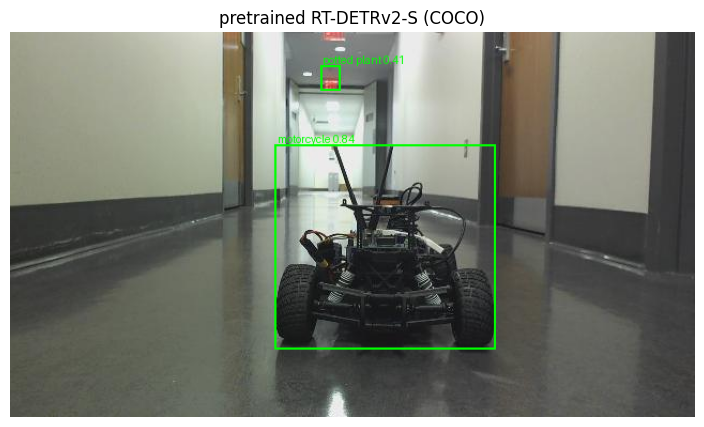

In [ ]:
coco_model = load_detector(cfg.checkpoint)
sample = Image.open(F110_DIR + "/4.jpg") if DATA_FORMAT == "f110_npy" else Image.open(
    next(p for p in (Path(YOLO_ROOT) / "images").rglob("*") if p.suffix.lower() in (".jpg", ".png")))
dets = detect(coco_model, [sample], threshold=0.4)[0]
for d in dets:
    print(f"{d['label']:>12s} {d['score']:.2f}  box={tuple(round(x, 1) for x in d['box'])}")
draw_detections(sample, dets, title="pretrained RT-DETRv2-S (COCO)");

## 4. Dataset

A box is (`class_id, [x, y, w, h]`) in pixels.
The data augmentation includes random distortion, zoom out, cropping, resizing, etc.

** 81 classes** (if we keep `cfg.keep_coco_classes = True`) but only use the dataset which has labels for class then the model will suffer in performance for other classes. `coco_pseudo_labels` prevents that without needing the COCO dataset: the frozen COCO
model labels every image once, and its detections (score > `cfg.pseudo_label_threshold`) are added to the labels.
A detection overlapping a labelled box is dropped: the COCO model may call the F1/10th car a "car" or a
"motorcycle", and that box already has its label. The val split's pseudo-labels, without the car, form
`coco_val_ds`

In [ ]:
# @title 4. Dataset (provided)
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms.v2 as T
import torchvision.transforms.v2.functional as F
import PIL
import PIL.Image
from typing import Any, Dict, List, Optional
from torch import Tensor


from torchvision.transforms.v2 import SanitizeBoundingBoxes
from torchvision.transforms.v2.functional import get_size
from torchvision.tv_tensors import (
    BoundingBoxes, BoundingBoxFormat, Mask, Image, Video)
_boxes_keys = ['format', 'canvas_size']


def convert_to_tv_tensor(tensor: Tensor, key: str, box_format='xyxy', spatial_size=None) -> Tensor:
    """
    Args:
        tensor (Tensor): input tensor
        key (str): transform to key

    Return:
        Dict[str, TV_Tensor]
    """
    assert key in ('boxes', 'masks', ), "Only support 'boxes' and 'masks'"

    if key == 'boxes':
        box_format = getattr(BoundingBoxFormat, box_format.upper())
        _kwargs = dict(zip(_boxes_keys, [box_format, spatial_size]))
        return BoundingBoxes(tensor, **_kwargs)

    if key == 'masks':
       return Mask(tensor)


class EmptyTransform(T.Transform):
    def __init__(self, ) -> None:
        super().__init__()

    def forward(self, *inputs):
        inputs = inputs if len(inputs) > 1 else inputs[0]
        return inputs


class RandomIoUCrop(T.RandomIoUCrop):
    def __init__(self, min_scale: float = 0.3, max_scale: float = 1, min_aspect_ratio: float = 0.5, max_aspect_ratio: float = 2, sampler_options: Optional[List[float]] = None, trials: int = 40, p: float = 1.0):
        super().__init__(min_scale, max_scale, min_aspect_ratio, max_aspect_ratio, sampler_options, trials)
        self.p = p

    def __call__(self, *inputs: Any) -> Any:
        if torch.rand(1) >= self.p:
            return inputs if len(inputs) > 1 else inputs[0]

        return super().forward(*inputs)


class ConvertBoxes(T.Transform):
    _transformed_types = (
        BoundingBoxes,
    )
    def __init__(self, fmt='', normalize=False) -> None:
        super().__init__()
        self.fmt = fmt
        self.normalize = normalize

    def _transform(self, inpt: Any, params: Dict[str, Any]) -> Any:
        spatial_size = getattr(inpt, _boxes_keys[1])
        if self.fmt:
            in_fmt = inpt.format.value.lower()
            inpt = torchvision.ops.box_convert(inpt, in_fmt=in_fmt, out_fmt=self.fmt.lower())
            inpt = convert_to_tv_tensor(inpt, key='boxes', box_format=self.fmt.upper(), spatial_size=spatial_size)

        if self.normalize:
            inpt = inpt / torch.tensor(spatial_size[::-1]).tile(2)[None]

        return inpt

    def transform(self, inpt: Any, params: Dict[str, Any]) -> Any:
        return self._transform(inpt, params)


class ConvertPILImage(T.Transform):
    _transformed_types = (
        PIL.Image.Image,
    )
    def __init__(self, dtype='float32', scale=True) -> None:
        super().__init__()
        self.dtype = dtype
        self.scale = scale

    def _transform(self, inpt: Any, params: Dict[str, Any]) -> Any:
        inpt = F.pil_to_tensor(inpt)
        if self.dtype == 'float32':
            inpt = inpt.float()

        if self.scale:
            inpt = inpt / 255.

        inpt = Image(inpt)

        return inpt

    def transform(self, inpt: Any, params: Dict[str, Any]) -> Any:
        return self._transform(inpt, params)


class Compose(T.Compose):
    def __init__(self, ops, policy=None) -> None:
        transforms = []
        if ops is not None:
            for op in ops:
                if isinstance(op, dict):
                    name = op.pop('type')
                    transfom = getattr(GLOBAL_CONFIG[name]['_pymodule'], GLOBAL_CONFIG[name]['_name'])(**op)
                    transforms.append(transfom)
                    op['type'] = name

                elif isinstance(op, nn.Module):
                    transforms.append(op)

                else:
                    raise ValueError('')
        else:
            transforms =[EmptyTransform(), ]

        super().__init__(transforms=transforms)

        if policy is None:
            policy = {'name': 'default'}

        self.policy = policy
        self.global_samples = 0

    def forward(self, *inputs: Any) -> Any:
        return self.get_forward(self.policy['name'])(*inputs)

    def get_forward(self, name):
        forwards = {
            'default': self.default_forward,
            'stop_epoch': self.stop_epoch_forward,
            'stop_sample': self.stop_sample_forward,
        }
        return forwards[name]

    def default_forward(self, *inputs: Any) -> Any:
        sample = inputs if len(inputs) > 1 else inputs[0]
        for transform in self.transforms:
            sample = transform(sample)
        return sample

    def stop_epoch_forward(self, *inputs: Any):
        sample = inputs if len(inputs) > 1 else inputs[0]
        dataset = sample[-1]

        cur_epoch = dataset.epoch
        policy_ops = self.policy['ops']
        policy_epoch = self.policy['epoch']

        for transform in self.transforms:
            if type(transform).__name__ in policy_ops and cur_epoch >= policy_epoch:
                pass
            else:
                sample = transform(sample)

        return sample


    def stop_sample_forward(self, *inputs: Any):
        sample = inputs if len(inputs) > 1 else inputs[0]
        dataset = sample[-1]

        cur_epoch = dataset.epoch
        policy_ops = self.policy['ops']
        policy_sample = self.policy['sample']

        for transform in self.transforms:
            if type(transform).__name__ in policy_ops and self.global_samples >= policy_sample:
                pass
            else:
                sample = transform(sample)

        self.global_samples += 1

        return sample

Writing rtdetrv2_transforms.py


In [ ]:
# @title 4. Dataset (provided)
import random


class ConvertCocoPolysToMask(object):
    def __init__(self, return_masks=False):
        self.return_masks = return_masks

    def __call__(self, image: Image.Image, target, **kwargs):
        w, h = image.size

        image_id = target["image_id"]
        image_id = torch.tensor([image_id])

        anno = target["annotations"]

        anno = [obj for obj in anno if 'iscrowd' not in obj or obj['iscrowd'] == 0]

        boxes = [obj["bbox"] for obj in anno]
        # guard against no boxes via resizing
        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        boxes[:, 2:] += boxes[:, :2]
        boxes[:, 0::2].clamp_(min=0, max=w)
        boxes[:, 1::2].clamp_(min=0, max=h)

        category2label = kwargs.get('category2label', None)
        if category2label is not None:
            labels = [category2label[obj["category_id"]] for obj in anno]
        else:
            labels = [obj["category_id"] for obj in anno]

        labels = torch.tensor(labels, dtype=torch.int64)

        if self.return_masks:
            segmentations = [obj["segmentation"] for obj in anno]
            masks = convert_coco_poly_to_mask(segmentations, h, w)

        keypoints = None
        if anno and "keypoints" in anno[0]:
            keypoints = [obj["keypoints"] for obj in anno]
            keypoints = torch.as_tensor(keypoints, dtype=torch.float32)
            num_keypoints = keypoints.shape[0]
            if num_keypoints:
                keypoints = keypoints.view(num_keypoints, -1, 3)

        keep = (boxes[:, 3] > boxes[:, 1]) & (boxes[:, 2] > boxes[:, 0])
        boxes = boxes[keep]
        labels = labels[keep]
        if self.return_masks:
            masks = masks[keep]
        if keypoints is not None:
            keypoints = keypoints[keep]

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        if self.return_masks:
            target["masks"] = masks
        target["image_id"] = image_id
        if keypoints is not None:
            target["keypoints"] = keypoints

        # for conversion to coco api
        area = torch.tensor([obj["area"] for obj in anno])
        iscrowd = torch.tensor([obj["iscrowd"] if "iscrowd" in obj else 0 for obj in anno])
        target["area"] = area[keep]
        target["iscrowd"] = iscrowd[keep]

        target["orig_size"] = torch.as_tensor([int(w), int(h)])

        return image, target


class BaseCollateFunction(object):
    def set_epoch(self, epoch):
        self._epoch = epoch

    @property
    def epoch(self):
        return self._epoch if hasattr(self, '_epoch') else -1

    def __call__(self, items):
        raise NotImplementedError('')


class BatchImageCollateFunction(BaseCollateFunction):
    def __init__(
        self,
        scales=None,
        stop_epoch=None,
    ) -> None:
        super().__init__()
        self.scales = scales
        self.stop_epoch = stop_epoch if stop_epoch is not None else 100000000

    def __call__(self, items):
        images = torch.cat([x[0][None] for x in items], dim=0)
        targets = [x[1] for x in items]

        if self.scales is not None and self.epoch < self.stop_epoch:

            sz = random.choice(self.scales)
            images = F.interpolate(images, size=sz)
            if 'masks' in targets[0]:
                for tg in targets:
                    tg['masks'] = F.interpolate(tg['masks'], size=sz, mode='nearest')
                raise NotImplementedError('')

        return images, targets

In [ ]:
# @title 4. Dataset (provided)

import importlib
import torchvision.transforms.v2 as T2
import rtdetrv2_transforms
importlib.reload(rtdetrv2_transforms)
from rtdetrv2_transforms import Compose, RandomIoUCrop, ConvertPILImage, ConvertBoxes, convert_to_tv_tensor


def train_transforms(image_size=640, stop_epoch=117):
    return Compose(ops=[
        T2.RandomPhotometricDistort(p=0.5),
        T2.RandomZoomOut(fill=0),
        RandomIoUCrop(p=0.8),
        T2.SanitizeBoundingBoxes(min_size=1),
        T2.RandomHorizontalFlip(),
        T2.Resize(size=[image_size, image_size]),
        T2.SanitizeBoundingBoxes(min_size=1),
        ConvertPILImage(dtype='float32', scale=True),
        ConvertBoxes(fmt='cxcywh', normalize=True),
    ], policy={'name': 'stop_epoch', 'epoch': stop_epoch,
               'ops': ['RandomPhotometricDistort', 'RandomZoomOut', 'RandomIoUCrop']})


def val_transforms(image_size=640):
    return Compose(ops=[T2.Resize(size=[image_size, image_size]), ConvertPILImage(dtype='float32', scale=True)])


IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def clip_xywh(x, y, w, h, width, height):
    x0, y0 = np.clip(x, 0, width), np.clip(y, 0, height)
    x1, y1 = np.clip(x + w, 0, width), np.clip(y + h, 0, height)
    return [float(x0), float(y0), float(x1 - x0), float(y1 - y0)] if x1 - x0 > 1 and y1 - y0 > 1 else None


def load_f110_npy(folder, labels_file="labels.npy", class_id=0):
    folder = Path(folder)
    labels = np.load(folder / labels_file)
    paths, boxes = [], []
    for i, (cx, cy, w, h) in enumerate(labels):
        p = folder / f"{i}.jpg"
        if not p.exists():
            continue
        b = clip_xywh(cx - w / 2, cy - h / 2, w, h, *Image.open(p).size)
        paths.append(p)
        boxes.append([(class_id, b)] if b else [])
    print(f"{folder.name}: {len(paths)} images, {sum(map(len, boxes))} boxes")
    return paths, boxes


def load_yolo_data_yaml(data_root):
    # Returns (class_names, {split: images_dir}).
    data_root = Path(data_root)
    d = yaml.safe_load((data_root / "data.yaml").read_text())
    names = d["names"]
    if isinstance(names, dict):                            # {0: name, 1: name}
        names = [names[k] for k in sorted(names, key=int)]
    base = Path(d.get("path") or data_root)
    base = base if base.is_absolute() and base.exists() else data_root
    splits = {s: base / d.get(s, f"images/{s}") for s in ("train", "val", "test")}
    return list(names), {k: v for k, v in splits.items() if v.exists()}


def yolo_label_path(image_path):
    # .../images/<split>/x.png -> .../labels/<split>/x.txt  (Ultralytics convention)
    parts = list(image_path.parts)
    idx = len(parts) - 1 - parts[::-1].index("images")
    parts[idx] = "labels"
    return Path(*parts).with_suffix(".txt")


def read_yolo_labels(txt_path, width, height):
    boxes = []
    if not txt_path.exists():
        return boxes
    for line in txt_path.read_text().splitlines():
        vals = line.split()
        if len(vals) < 5:
            continue
        cls, nums = int(float(vals[0])), np.array(vals[1:], dtype=float)
        if nums.size == 4:
            cx, cy, w, h = nums
        else:                                              # segmentation polygon x1 y1 x2 y2 ...
            xs, ys = nums[0::2], nums[1::2]
            cx, cy, w, h = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2, np.ptp(xs), np.ptp(ys)
        b = clip_xywh((cx - w / 2) * width, (cy - h / 2) * height, w * width, h * height, width, height)
        if b:
            boxes.append((cls, b))
    return boxes


def load_yolo_split(images_dir):
    paths = sorted(p for p in Path(images_dir).rglob("*") if p.suffix.lower() in IMAGE_EXTS)
    return paths, [read_yolo_labels(yolo_label_path(p), *Image.open(p).size) for p in paths]


def random_split(n, val_fraction=0.15, seed=0):
    # Indices for train / val: a random val_fraction of the images is held out.
    idx = list(range(n))
    random.Random(seed).shuffle(idx)
    n_val = max(1, round(val_fraction * n))
    return sorted(idx[n_val:]), sorted(idx[:n_val])


class DetectionDataset(Dataset):
    # ours: (paths, boxes) lists, loaded like the repo's CocoDetection (src/data/dataset/coco_dataset.py:
    # load_item / __getitem__) and with the epoch of src/data/dataset/_dataset.py for the stop_epoch policy
    def __init__(self, paths, boxes, num_classes, transforms=None):
        if not paths:
            raise ValueError("empty dataset")
        bad = {c for bs in boxes for c, _ in bs if not 0 <= c < num_classes}
        if bad:
            raise ValueError(f"class ids {sorted(bad)} outside 0..{num_classes - 1}")
        self.paths, self.boxes, self._transforms = list(paths), list(boxes), transforms
        self.prepare = ConvertCocoPolysToMask(return_masks=False)

    def set_epoch(self, epoch) -> None:
        self._epoch = epoch

    @property
    def epoch(self):
        return self._epoch if hasattr(self, '_epoch') else -1

    def __len__(self):
        return len(self.paths)

    def load(self, i):
        # the original image and its boxes [(class_id, [x, y, w, h])], for evaluation and plotting
        return Image.open(self.paths[i]).convert("RGB"), list(self.boxes[i])

    def load_item(self, idx):
        image, boxes = self.load(idx)
        target = {"image_id": idx,
                  "annotations": [{"bbox": b, "category_id": c, "area": b[2] * b[3], "iscrowd": 0} for c, b in boxes]}
        image, target = self.prepare(image, target)
        target['idx'] = torch.tensor([idx])
        target['boxes'] = convert_to_tv_tensor(target['boxes'], key='boxes', spatial_size=image.size[::-1])
        return image, target

    def __getitem__(self, idx):
        img, target = self.load_item(idx)
        if self._transforms is not None:
            img, target, _ = self._transforms(img, target, self)
        return img, target


def xywh_to_xyxy(b):
    return (b[0], b[1], b[0] + b[2], b[1] + b[3])


def scalar_box_iou(a, b):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)


def coco_pseudo_labels(teacher, paths, boxes, threshold=0.5, overlap=0.3, batch_size=8):
    ids = {name: i for i, name in enumerate(teacher.class_names)}
    out = []
    for s in range(0, len(paths), batch_size):
        images = [Image.open(p).convert("RGB") for p in paths[s:s + batch_size]]
        for image, dets, own in zip(images, detect(teacher, images, threshold), boxes[s:s + batch_size]):
            new = []
            for d in dets:
                u1, v1, u2, v2 = d["box"]
                b = clip_xywh(u1, v1, u2 - u1, v2 - v1, *image.size)
                if b and all(scalar_box_iou(xywh_to_xyxy(b), xywh_to_xyxy(o)) <= overlap for _, o in own):
                    new.append((ids[d["label"]], b))
            out.append(new)
    found = Counter(teacher.class_names[c] for bs in out for c, _ in bs)
    print(f"COCO pseudo-labels: {sum(found.values())} boxes in {sum(map(bool, out))}/{len(out)} images",
          dict(found.most_common(8)))
    return out


def show_dataset_samples(ds, class_names, n=4):
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 4.5))
    for ax, i in zip(np.atleast_1d(axes), random.sample(range(len(ds)), min(n, len(ds)))):
        image, target = ds[i]
        h, w = image.shape[-2:]
        boxes = torchvision.ops.box_convert(torch.as_tensor(target["boxes"]), "cxcywh", "xyxy") * torch.tensor([w, h, w, h])
        dets = [{"label": class_names[int(c)], "score": 1.0, "box": tuple(b.tolist())}
                for c, b in zip(target["labels"], boxes)]
        draw_detections(Image.fromarray((image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)), dets, ax=ax,
                        title=ds.paths[i].name)
    plt.tight_layout()

f110_dataset_20220209: 1792 images, 1792 boxes
Load model.state_dict, {'missed': [], 'unmatched': []}
COCO pseudo-labels: 123 boxes in 76/250 images {'refrigerator': 46, 'chair': 37, 'person': 9, 'tv': 6, 'bed': 5, 'bottle': 5, 'couch': 3, 'vase': 2}
COCO pseudo-labels: 1123 boxes in 602/1542 images {'refrigerator': 264, 'chair': 231, 'person': 160, 'suitcase': 90, 'bottle': 77, 'car': 74, 'tv': 49, 'couch': 39}
81 classes, new: {80: 'f1tenth_car'} | train 1542 | val 250 | COCO retention set 250


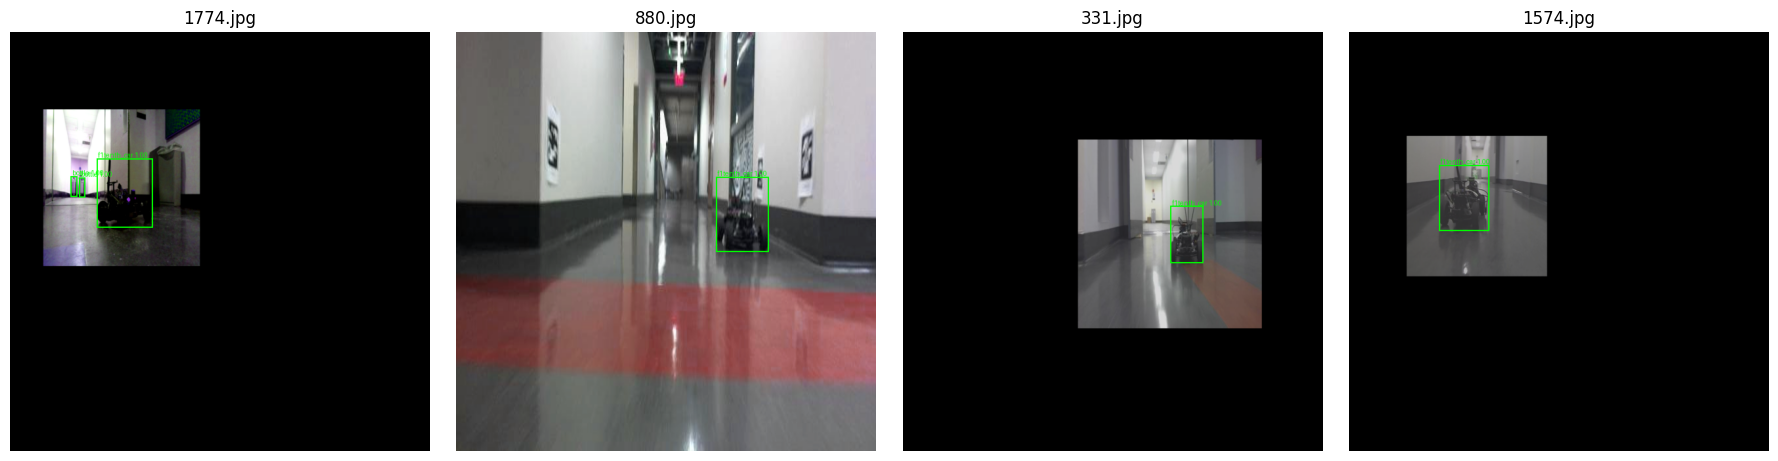

In [ ]:
# @title 4. Dataset (provided)
if DATA_FORMAT == "f110_npy":
    new_names = CLASS_NAMES
    paths, boxes = load_f110_npy(F110_DIR)
    tr, va = random_split(len(paths), cfg.val_fraction, cfg.seed)
    splits = {"train": ([paths[i] for i in tr], [boxes[i] for i in tr]),
              "val": ([paths[i] for i in va], [boxes[i] for i in va])}
else:
    new_names, dirs = load_yolo_data_yaml(YOLO_ROOT)
    splits = {s: load_yolo_split(dirs.get(s, dirs["train"])) for s in ("train", "val")}

coco_val_ds = None
val_tf = val_transforms(cfg.image_size)
if cfg.keep_coco_classes:
    teacher = load_detector(cfg.checkpoint)
    n_coco = len(teacher.class_names)
    class_names = teacher.class_names + list(new_names)        # dataset class i -> 80 + i
    splits = {s: (p, [[(c + n_coco, b) for c, b in bs] for bs in bxs]) for s, (p, bxs) in splits.items()}
    val_pseudo = coco_pseudo_labels(teacher, *splits["val"], cfg.pseudo_label_threshold)
    if any(val_pseudo):
        coco_val_ds = DetectionDataset(splits["val"][0], val_pseudo, len(class_names), val_tf)
    if cfg.pseudo_labels:
        p, bxs = splits["train"]
        pseudo = coco_pseudo_labels(teacher, p, bxs, cfg.pseudo_label_threshold)
        splits["train"] = (p, [own + extra for own, extra in zip(bxs, pseudo)])
    del teacher
else:
    class_names = list(new_names)

train_ds = DetectionDataset(*splits["train"], len(class_names),
                            train_transforms(cfg.image_size, stop_epoch=cfg.epochs - cfg.no_aug_epochs))
val_ds = DetectionDataset(*splits["val"], len(class_names), val_tf)
print(f"{len(class_names)} classes, new: {dict(list(enumerate(class_names))[-len(new_names):])} | train",
      len(train_ds), "| val", len(val_ds), "| COCO retention set", len(coco_val_ds) if coco_val_ds else None)
print("training samples after data augmentation and pseudo labels")
show_dataset_samples(train_ds, class_names)

## 5. Model for the new class(es)



In [ ]:
def build_model_for_new_classes(class_names, checkpoint=cfg.checkpoint, image_size=cfg.image_size,
                                freeze_backbone=False, init_new_from=None, device=device):
    model = build_rtdetrv2(class_names, checkpoint=checkpoint, image_size=image_size, init_new_from=init_new_from)
    model.image_size = image_size
    if freeze_backbone:
        for n, p in model.named_parameters():
            if n.startswith("backbone."):
                p.requires_grad_(False)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{n_train / 1e6:.1f} M trainable params, {len(class_names)} classes, input {image_size}")
    return model.to(device)


if cfg.keep_coco_classes and "coco_model" in globals():
    check_model = build_model_for_new_classes(class_names, image_size=640, init_new_from=cfg.init_new_class_from)
    x = preprocess([sample]).to(device)
    with torch.no_grad():
        coco_out, new_out = coco_model.eval()(x), check_model.eval()(x)
    n = len(coco_model.class_names)
    print("logits", tuple(new_out["pred_logits"].shape), "| max |difference| on the COCO classes:",
          (new_out["pred_logits"][..., :n] - coco_out["pred_logits"]).abs().max().item(), "| boxes:",
          (new_out["pred_boxes"] - coco_out["pred_boxes"]).abs().max().item())
    del check_model

kept COCO's 80 classes, added ['f1tenth_car']
Load model.state_dict, {'missed': [], 'unmatched': []}
20.2 M trainable params, 81 classes, input 640
logits (1, 300, 81) | max |difference| on the COCO classes: 0.0 | boxes: 0.0


## 6. Loss Function

1. **Hungarian matching** (class `HungarianMatcher`): For each image, the one-to-one assignment of predictions to GT boxes with the lowest cost `2 * class + 5 * L1 + 2 * (-GIoU)`. Each GT box gets exactly one prediction; the other queries are trained as background. Because duplicates are punished, no NMS is needed at test time.
2. **Varifocal loss** (function `loss_labels_vfl`): the target score of a matched query is the **IoU** of its box with the GT box, not 1, so a high score also means a well-placed box; unmatched queries are pushed to 0, with easy negatives down-weighted.
3. **L1 + GIoU** (function `loss_boxes`) on the matched boxes, in normalised (cx, cy, w, h).


In [ ]:
# @title 6. Loss Function (provided)
def is_dist_available_and_initialized():
    if not torch.distributed.is_available():
        return False
    if not torch.distributed.is_initialized():
        return False
    return True


def get_world_size():
    if not is_dist_available_and_initialized():
        return 1
    return torch.distributed.get_world_size()

class HungarianMatcher(nn.Module):
    """This class computes an assignment between the targets and the predictions of the network

    For efficiency reasons, the targets don't include the no_object. Because of this, in general,
    there are more predictions than targets. In this case, we do a 1-to-1 matching of the best predictions,
    while the others are un-matched (and thus treated as non-objects).
    """

    __share__ = ['use_focal_loss', ]

    def __init__(self, weight_dict, use_focal_loss=False, alpha=0.25, gamma=2.0):
        """Creates the matcher

        Params:
            cost_class: This is the relative weight of the classification error in the matching cost
            cost_bbox: This is the relative weight of the L1 error of the bounding box coordinates in the matching cost
            cost_giou: This is the relative weight of the giou loss of the bounding box in the matching cost
        """
        super().__init__()
        self.cost_class = weight_dict['cost_class']
        self.cost_bbox = weight_dict['cost_bbox']
        self.cost_giou = weight_dict['cost_giou']

        self.use_focal_loss = use_focal_loss
        self.alpha = alpha
        self.gamma = gamma

        assert self.cost_class != 0 or self.cost_bbox != 0 or self.cost_giou != 0, "all costs cant be 0"

    @torch.no_grad()
    def forward(self, outputs: Dict[str, torch.Tensor], targets):
        """ Performs the matching

        Params:
            outputs: This is a dict that contains at least these entries:
                 "pred_logits": Tensor of dim [batch_size, num_queries, num_classes] with the classification logits
                 "pred_boxes": Tensor of dim [batch_size, num_queries, 4] with the predicted box coordinates

            targets: This is a list of targets (len(targets) = batch_size), where each target is a dict containing:
                 "labels": Tensor of dim [num_target_boxes] (where num_target_boxes is the number of ground-truth
                           objects in the target) containing the class labels
                 "boxes": Tensor of dim [num_target_boxes, 4] containing the target box coordinates

        Returns:
            A list of size batch_size, containing tuples of (index_i, index_j) where:
                - index_i is the indices of the selected predictions (in order)
                - index_j is the indices of the corresponding selected targets (in order)
            For each batch element, it holds:
                len(index_i) = len(index_j) = min(num_queries, num_target_boxes)
        """
        bs, num_queries = outputs["pred_logits"].shape[:2]

        # We flatten to compute the cost matrices in a batch
        if self.use_focal_loss:
            out_prob = F.sigmoid(outputs["pred_logits"].flatten(0, 1))
        else:
            out_prob = outputs["pred_logits"].flatten(0, 1).softmax(-1)  # [batch_size * num_queries, num_classes]

        out_bbox = outputs["pred_boxes"].flatten(0, 1)  # [batch_size * num_queries, 4]

        # Also concat the target labels and boxes
        tgt_ids = torch.cat([v["labels"] for v in targets])
        tgt_bbox = torch.cat([v["boxes"] for v in targets])

        # Compute the classification cost. Contrary to the loss, we don't use the NLL,
        # but approximate it in 1 - proba[target class].
        # The 1 is a constant that doesn't change the matching, it can be ommitted.
        if self.use_focal_loss:
            out_prob = out_prob[:, tgt_ids]
            neg_cost_class = (1 - self.alpha) * (out_prob ** self.gamma) * (-(1 - out_prob + 1e-8).log())
            pos_cost_class = self.alpha * ((1 - out_prob) ** self.gamma) * (-(out_prob + 1e-8).log())
            cost_class = pos_cost_class - neg_cost_class
        else:
            cost_class = -out_prob[:, tgt_ids]

        # Compute the L1 cost between boxes
        cost_bbox = torch.cdist(out_bbox, tgt_bbox, p=1)

        # Compute the giou cost betwen boxes
        cost_giou = -generalized_box_iou(box_cxcywh_to_xyxy(out_bbox), box_cxcywh_to_xyxy(tgt_bbox))

        # Final cost matrix
        C = self.cost_bbox * cost_bbox + self.cost_class * cost_class + self.cost_giou * cost_giou
        C = C.view(bs, num_queries, -1).cpu()

        sizes = [len(v["boxes"]) for v in targets]
        indices = [linear_sum_assignment(c[i]) for i, c in enumerate(C.split(sizes, -1))]
        indices = [(torch.as_tensor(i, dtype=torch.int64), torch.as_tensor(j, dtype=torch.int64)) for i, j in indices]

        return {'indices': indices}


class RTDETRCriterionv2(nn.Module):
    """ This class computes the loss for DETR.
    The process happens in two steps:
        1) we compute hungarian assignment between ground truth boxes and the outputs of the model
        2) we supervise each pair of matched ground-truth / prediction (supervise class and box)
    """
    __share__ = ['num_classes', ]
    __inject__ = ['matcher', ]

    def __init__(self, \
        matcher,
        weight_dict,
        losses,
        alpha=0.2,
        gamma=2.0,
        num_classes=80,
        boxes_weight_format=None,
        share_matched_indices=False):
        """Create the criterion.
        Parameters:
            matcher: module able to compute a matching between targets and proposals
            num_classes: number of object categories, omitting the special no-object category
            weight_dict: dict containing as key the names of the losses and as values their relative weight.
            eos_coef: relative classification weight applied to the no-object category
            losses: list of all the losses to be applied. See get_loss for list of available losses.
            boxes_weight_format: format for boxes weight (iou, )
        """
        super().__init__()
        self.num_classes = num_classes
        self.matcher = matcher
        self.weight_dict = weight_dict
        self.losses = losses
        self.boxes_weight_format = boxes_weight_format
        self.share_matched_indices = share_matched_indices
        self.alpha = alpha
        self.gamma = gamma

    def loss_labels_focal(self, outputs, targets, indices, num_boxes):
        assert 'pred_logits' in outputs
        src_logits = outputs['pred_logits']
        idx = self._get_src_permutation_idx(indices)
        target_classes_o = torch.cat([t["labels"][J] for t, (_, J) in zip(targets, indices)])
        target_classes = torch.full(src_logits.shape[:2], self.num_classes,
                                    dtype=torch.int64, device=src_logits.device)
        target_classes[idx] = target_classes_o
        target = F.one_hot(target_classes, num_classes=self.num_classes+1)[..., :-1]
        loss = torchvision.ops.sigmoid_focal_loss(src_logits, target, self.alpha, self.gamma, reduction='none')
        loss = loss.mean(1).sum() * src_logits.shape[1] / num_boxes

        return {'loss_focal': loss}

    def loss_labels_vfl(self, outputs, targets, indices, num_boxes, values=None):
        assert 'pred_boxes' in outputs
        idx = self._get_src_permutation_idx(indices)
        if values is None:
            src_boxes = outputs['pred_boxes'][idx]
            target_boxes = torch.cat([t['boxes'][i] for t, (_, i) in zip(targets, indices)], dim=0)
            ious, _ = box_iou(box_cxcywh_to_xyxy(src_boxes), box_cxcywh_to_xyxy(target_boxes))
            ious = torch.diag(ious).detach()
        else:
            ious = values

        src_logits = outputs['pred_logits']
        target_classes_o = torch.cat([t["labels"][J] for t, (_, J) in zip(targets, indices)])
        target_classes = torch.full(src_logits.shape[:2], self.num_classes,
                                    dtype=torch.int64, device=src_logits.device)
        target_classes[idx] = target_classes_o
        target = F.one_hot(target_classes, num_classes=self.num_classes + 1)[..., :-1]

        target_score_o = torch.zeros_like(target_classes, dtype=src_logits.dtype)
        target_score_o[idx] = ious.to(target_score_o.dtype)
        target_score = target_score_o.unsqueeze(-1) * target

        pred_score = F.sigmoid(src_logits).detach()
        weight = self.alpha * pred_score.pow(self.gamma) * (1 - target) + target_score

        loss = F.binary_cross_entropy_with_logits(src_logits, target_score, weight=weight, reduction='none')
        loss = loss.mean(1).sum() * src_logits.shape[1] / num_boxes
        return {'loss_vfl': loss}

    def loss_boxes(self, outputs, targets, indices, num_boxes, boxes_weight=None):
        """Compute the losses related to the bounding boxes, the L1 regression loss and the GIoU loss
           targets dicts must contain the key "boxes" containing a tensor of dim [nb_target_boxes, 4]
           The target boxes are expected in format (center_x, center_y, w, h), normalized by the image size.
        """
        assert 'pred_boxes' in outputs
        idx = self._get_src_permutation_idx(indices)
        src_boxes = outputs['pred_boxes'][idx]
        target_boxes = torch.cat([t['boxes'][i] for t, (_, i) in zip(targets, indices)], dim=0)

        losses = {}
        loss_bbox = F.l1_loss(src_boxes, target_boxes, reduction='none')
        losses['loss_bbox'] = loss_bbox.sum() / num_boxes

        loss_giou = 1 - torch.diag(generalized_box_iou(\
            box_cxcywh_to_xyxy(src_boxes), box_cxcywh_to_xyxy(target_boxes)))
        loss_giou = loss_giou if boxes_weight is None else loss_giou * boxes_weight
        losses['loss_giou'] = loss_giou.sum() / num_boxes
        return losses

    def _get_src_permutation_idx(self, indices):
        # permute predictions following indices
        batch_idx = torch.cat([torch.full_like(src, i) for i, (src, _) in enumerate(indices)])
        src_idx = torch.cat([src for (src, _) in indices])
        return batch_idx, src_idx

    def _get_tgt_permutation_idx(self, indices):
        # permute targets following indices
        batch_idx = torch.cat([torch.full_like(tgt, i) for i, (_, tgt) in enumerate(indices)])
        tgt_idx = torch.cat([tgt for (_, tgt) in indices])
        return batch_idx, tgt_idx

    def get_loss(self, loss, outputs, targets, indices, num_boxes, **kwargs):
        loss_map = {
            'boxes': self.loss_boxes,
            'focal': self.loss_labels_focal,
            'vfl': self.loss_labels_vfl,
        }
        assert loss in loss_map, f'do you really want to compute {loss} loss?'
        return loss_map[loss](outputs, targets, indices, num_boxes, **kwargs)

    def forward(self, outputs, targets, **kwargs):
        """ This performs the loss computation.
        Parameters:
             outputs: dict of tensors, see the output specification of the model for the format
             targets: list of dicts, such that len(targets) == batch_size.
                      The expected keys in each dict depends on the losses applied, see each loss' doc
        """
        outputs_without_aux = {k: v for k, v in outputs.items() if 'aux' not in k}

        # Compute the average number of target boxes accross all nodes, for normalization purposes
        num_boxes = sum(len(t["labels"]) for t in targets)
        num_boxes = torch.as_tensor([num_boxes], dtype=torch.float, device=next(iter(outputs.values())).device)
        if is_dist_available_and_initialized():
            torch.distributed.all_reduce(num_boxes)
        num_boxes = torch.clamp(num_boxes / get_world_size(), min=1).item()

        # Retrieve the matching between the outputs of the last layer and the targets
        matched = self.matcher(outputs_without_aux, targets)
        indices = matched['indices']

        # Compute all the requested losses
        losses = {}
        for loss in self.losses:
            meta = self.get_loss_meta_info(loss, outputs, targets, indices)
            l_dict = self.get_loss(loss, outputs, targets, indices, num_boxes, **meta)
            l_dict = {k: l_dict[k] * self.weight_dict[k] for k in l_dict if k in self.weight_dict}
            losses.update(l_dict)

        # In case of auxiliary losses, we repeat this process with the output of each intermediate layer.
        if 'aux_outputs' in outputs:
            for i, aux_outputs in enumerate(outputs['aux_outputs']):
                if not self.share_matched_indices:
                    matched = self.matcher(aux_outputs, targets)
                    indices = matched['indices']
                for loss in self.losses:
                    meta = self.get_loss_meta_info(loss, aux_outputs, targets, indices)
                    l_dict = self.get_loss(loss, aux_outputs, targets, indices, num_boxes, **meta)
                    l_dict = {k: l_dict[k] * self.weight_dict[k] for k in l_dict if k in self.weight_dict}
                    l_dict = {k + f'_aux_{i}': v for k, v in l_dict.items()}
                    losses.update(l_dict)

        # In case of cdn auxiliary losses. For rtdetr
        if 'dn_aux_outputs' in outputs:
            assert 'dn_meta' in outputs, ''
            indices = self.get_cdn_matched_indices(outputs['dn_meta'], targets)
            dn_num_boxes = num_boxes * outputs['dn_meta']['dn_num_group']
            for i, aux_outputs in enumerate(outputs['dn_aux_outputs']):
                for loss in self.losses:
                    meta = self.get_loss_meta_info(loss, aux_outputs, targets, indices)
                    l_dict = self.get_loss(loss, aux_outputs, targets, indices, dn_num_boxes, **meta)
                    l_dict = {k: l_dict[k] * self.weight_dict[k] for k in l_dict if k in self.weight_dict}
                    l_dict = {k + f'_dn_{i}': v for k, v in l_dict.items()}
                    losses.update(l_dict)

        # In case of encoder auxiliary losses. For rtdetr v2
        if 'enc_aux_outputs' in outputs:
            assert 'enc_meta' in outputs, ''
            class_agnostic = outputs['enc_meta']['class_agnostic']
            if class_agnostic:
                orig_num_classes = self.num_classes
                self.num_classes = 1
                enc_targets = copy.deepcopy(targets)
                for t in enc_targets:
                    t['labels'] = torch.zeros_like(t["labels"])
            else:
                enc_targets = targets

            for i, aux_outputs in enumerate(outputs['enc_aux_outputs']):
                matched = self.matcher(aux_outputs, targets)
                indices = matched['indices']
                for loss in self.losses:
                    meta = self.get_loss_meta_info(loss, aux_outputs, enc_targets, indices)
                    l_dict = self.get_loss(loss, aux_outputs, enc_targets, indices, num_boxes, **meta)
                    l_dict = {k: l_dict[k] * self.weight_dict[k] for k in l_dict if k in self.weight_dict}
                    l_dict = {k + f'_enc_{i}': v for k, v in l_dict.items()}
                    losses.update(l_dict)

            if class_agnostic:
                self.num_classes = orig_num_classes

        return losses

    def get_loss_meta_info(self, loss, outputs, targets, indices):
        if self.boxes_weight_format is None:
            return {}

        src_boxes = outputs['pred_boxes'][self._get_src_permutation_idx(indices)]
        target_boxes = torch.cat([t['boxes'][j] for t, (_, j) in zip(targets, indices)], dim=0)

        if self.boxes_weight_format == 'iou':
            iou, _ = box_iou(box_cxcywh_to_xyxy(src_boxes.detach()), box_cxcywh_to_xyxy(target_boxes))
            iou = torch.diag(iou)
        elif self.boxes_weight_format == 'giou':
            iou = torch.diag(generalized_box_iou(\
                box_cxcywh_to_xyxy(src_boxes.detach()), box_cxcywh_to_xyxy(target_boxes)))
        else:
            raise AttributeError()

        if loss in ('boxes', ):
            meta = {'boxes_weight': iou}
        elif loss in ('vfl', ):
            meta = {'values': iou}
        else:
            meta = {}

        return meta

    @staticmethod
    def get_cdn_matched_indices(dn_meta, targets):
        """get_cdn_matched_indices
        """
        dn_positive_idx, dn_num_group = dn_meta["dn_positive_idx"], dn_meta["dn_num_group"]
        num_gts = [len(t['labels']) for t in targets]
        device = targets[0]['labels'].device

        dn_match_indices = []
        for i, num_gt in enumerate(num_gts):
            if num_gt > 0:
                gt_idx = torch.arange(num_gt, dtype=torch.int64, device=device)
                gt_idx = gt_idx.tile(dn_num_group)
                assert len(dn_positive_idx[i]) == len(gt_idx)
                dn_match_indices.append((dn_positive_idx[i], gt_idx))
            else:
                dn_match_indices.append((torch.zeros(0, dtype=torch.int64, device=device), \
                    torch.zeros(0, dtype=torch.int64,  device=device)))

        return dn_match_indices

## 7. Training and evaluation

Hyperparameters:
* **AdamW** lr 1e-4, betas (0.9, 0.999), weight decay 1e-4 except on norm layers. For r18 the backbone is trained at the same lr (the r50 config's 1e-5 backbone group is replaced).
* **LinearWarmup** over the first 2000 iterations, then **MultiStepLR** (milestone at epoch 1000, i.e. a constant
  lr for any realistic run), stepped once per epoch after the warm-up.

Metrics:
* `map`: The mAP is measured for class of interest (here f1tenth_car). mAP@50 is the mAP with IoU threshold 0.5. Increase in this metric suggests that the model is learning the new class.
* `coco_map50`: mAP@50 on `coco_val_ds`, i.e. the model's COCO-class detections against the COCO model's own detections on the val images. If you keep the coco classes (81 classes) and the coco_map50 drops, it means the model is forgetting, and high AP means the model still finds the same objects as before finetuning.
* `lab_accuracy`: the top-scoring box of the labelled class in each image is correct if, at the lab's 320x180 input scale, its centre is < 20 px from the ground truth and IoU > 0.5.

Note:
* The best checkpoint by mAP is written with `save_checkpoint` to `{out_dir}/best/rtdetrv2.pt` and
  `load_detector({out_dir}/'best')` reloads it.

**Things to try**: train once with `cfg.pseudo_labels = False` and compare `coco_map50` over the epochs.

In [ ]:
# @title 7. Training and evaluation (provided)
from copy import deepcopy
import re
from torch.optim.lr_scheduler import LRScheduler


def is_parallel(model) -> bool:
    # Returns True if model is of type DP or DDP
    return type(model) in (torch.nn.parallel.DataParallel, torch.nn.parallel.DistributedDataParallel)


def de_parallel(model) -> nn.Module:
    # De-parallelize a model: returns single-GPU model if model is of type DP or DDP
    return model.module if is_parallel(model) else model


import types
dist_utils = types.SimpleNamespace(de_parallel=de_parallel)

class ModelEMA(object):
    """
    Model Exponential Moving Average from https://github.com/rwightman/pytorch-image-models
    Keep a moving average of everything in the model state_dict (parameters and buffers).
    This is intended to allow functionality like
    https://www.tensorflow.org/api_docs/python/tf/train/ExponentialMovingAverage
    A smoothed version of the weights is necessary for some training schemes to perform well.
    This class is sensitive where it is initialized in the sequence of model init,
    GPU assignment and distributed training wrappers.
    """
    def __init__(self, model: nn.Module, decay: float=0.9999, warmups: int=2000, ):
        super().__init__()

        self.module = deepcopy(dist_utils.de_parallel(model)).eval()
        # if next(model.parameters()).device.type != 'cpu':
        #     self.module.half()  # FP16 EMA

        self.decay = decay
        self.warmups = warmups
        self.updates = 0  # number of EMA updates
        self.decay_fn = lambda x: decay * (1 - math.exp(-x / warmups))  # decay exponential ramp (to help early epochs)

        for p in self.module.parameters():
            p.requires_grad_(False)


    def update(self, model: nn.Module):
        # Update EMA parameters
        with torch.no_grad():
            self.updates += 1
            d = self.decay_fn(self.updates)
            msd = dist_utils.de_parallel(model).state_dict()
            for k, v in self.module.state_dict().items():
                if v.dtype.is_floating_point:
                    v *= d
                    v += (1 - d) * msd[k].detach()

    def to(self, *args, **kwargs):
        self.module = self.module.to(*args, **kwargs)
        return self

    def state_dict(self, ):
        return dict(module=self.module.state_dict(), updates=self.updates)

    def load_state_dict(self, state, strict=True):
        self.module.load_state_dict(state['module'], strict=strict)
        if 'updates' in state:
            self.updates = state['updates']

    def forwad(self, ):
        raise RuntimeError('ema...')

    def extra_repr(self) -> str:
        return f'decay={self.decay}, warmups={self.warmups}'

class Warmup(object):
    def __init__(self, lr_scheduler: LRScheduler, warmup_duration: int, last_step: int=-1) -> None:
        self.lr_scheduler = lr_scheduler
        self.warmup_end_values = [pg['lr'] for pg in lr_scheduler.optimizer.param_groups]
        self.last_step = last_step
        self.warmup_duration = warmup_duration
        self.step()

    def state_dict(self):
        return {k: v for k, v in self.__dict__.items() if k != 'lr_scheduler'}

    def load_state_dict(self, state_dict):
        self.__dict__.update(state_dict)

    def get_warmup_factor(self, step, **kwargs):
        raise NotImplementedError

    def step(self, ):
        self.last_step += 1
        if self.last_step >= self.warmup_duration:
            return
        factor = self.get_warmup_factor(self.last_step)
        for i, pg in enumerate(self.lr_scheduler.optimizer.param_groups):
            pg['lr'] = factor * self.warmup_end_values[i]

    def finished(self, ):
        if self.last_step >= self.warmup_duration:
            return True
        return False


class LinearWarmup(Warmup):
    def __init__(self, lr_scheduler: LRScheduler, warmup_duration: int, last_step: int = -1) -> None:
        super().__init__(lr_scheduler, warmup_duration, last_step)

    def get_warmup_factor(self, step):
        return min(1.0, (step + 1) / self.warmup_duration)

def get_optim_params(cfg: dict, model: nn.Module):
    """
    E.g.:
        ^(?=.*a)(?=.*b).*$  means including a and b
        ^(?=.*(?:a|b)).*$   means including a or b
        ^(?=.*a)(?!.*b).*$  means including a, but not b
    """
    assert 'type' in cfg, ''
    cfg = copy.deepcopy(cfg)

    if 'params' not in cfg:
        return model.parameters()

    assert isinstance(cfg['params'], list), ''

    param_groups = []
    visited = []
    for pg in cfg['params']:
        pattern = pg['params']
        params = {k: v for k, v in model.named_parameters() if v.requires_grad and len(re.findall(pattern, k)) > 0}
        pg['params'] = params.values()
        param_groups.append(pg)
        visited.extend(list(params.keys()))
        # print(params.keys())

    names = [k for k, v in model.named_parameters() if v.requires_grad]

    if len(visited) < len(names):
        unseen = set(names) - set(visited)
        params = {k: v for k, v in model.named_parameters() if v.requires_grad and k in unseen}
        param_groups.append({'params': params.values()})
        visited.extend(list(params.keys()))
        # print(params.keys())

    assert len(visited) == len(names), ''

    return param_groups

In [ ]:
# @title 7. Training and evaluation (provided)
from torchmetrics.detection import MeanAveragePrecision

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

@torch.no_grad()
def predict_dataset(model, ds, batch_size=8, threshold=0.0, num_workers=0):
    model.eval()
    device = next(model.parameters()).device
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=num_workers,
                        collate_fn=BatchImageCollateFunction())
    post = RTDETRPostProcessor(num_classes=len(model.class_names), use_focal_loss=True, num_top_queries=300)
    for samples, targets in loader:
        outputs = model(samples.to(device))
        orig_target_sizes = torch.stack([t["orig_size"] for t in targets], dim=0).to(device)
        for r, t in zip(post(outputs, orig_target_sizes), targets):
            keep = r["scores"] > threshold
            yield {k: v[keep].cpu() for k, v in r.items()}, ds.boxes[int(t["idx"])]


def evaluate(model, ds, batch_size=8):
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    metric.warn_on_many_detections = False
    for pred, boxes in predict_dataset(model, ds, batch_size):
        gt = {"boxes": torch.tensor([xywh_to_xyxy(b) for _, b in boxes], dtype=torch.float32).reshape(-1, 4),
              "labels": torch.tensor([c for c, _ in boxes], dtype=torch.long)}
        metric.update([pred], [gt])
    m = metric.compute()
    return {k: m[k].item() for k in ("map", "map_50", "map_75", "map_small", "map_medium", "map_large", "mar_100")}


def lab_accuracy(model, ds, conf=0.5, pos_thresh=20.0, iou_thresh=0.5, label_scale=2.0,
                 batch_size=8):
    correct = counted = 0
    for pred, t in predict_dataset(model, ds, batch_size, threshold=conf):
        if not t:
            continue
        counted += 1
        gt_class, gt_box = t[0]
        mine = pred["labels"] == gt_class
        if not mine.any():
            continue
        p = pred["boxes"][mine][pred["scores"][mine].argmax()].tolist()
        g = xywh_to_xyxy(gt_box)
        dc = math.hypot((p[0] + p[2] - g[0] - g[2]) / 2, (p[1] + p[3] - g[1] - g[3]) / 2) / label_scale
        correct += dc < pos_thresh and scalar_box_iou(p, g) > iou_thresh
    return correct / max(counted, 1)


def train(model, train_ds, val_ds, cfg=cfg, coco_val_ds=None):
    seed_everything(cfg.seed)
    out_dir = Path(cfg.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    device = next(model.parameters()).device
    loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=len(train_ds) > cfg.batch_size,
                        num_workers=cfg.num_workers, collate_fn=BatchImageCollateFunction(),
                        pin_memory=device.type == "cuda")

    matcher = HungarianMatcher(weight_dict={'cost_class': 2, 'cost_bbox': 5, 'cost_giou': 2}, use_focal_loss=True,
                               alpha=0.25, gamma=2.0)
    criterion = RTDETRCriterionv2(matcher, weight_dict={'loss_vfl': 1, 'loss_bbox': 5, 'loss_giou': 2},
                                  losses=['vfl', 'boxes'], alpha=0.75, gamma=2.0, num_classes=len(model.class_names))

    params = get_optim_params({'type': 'AdamW', 'params': [{'params': '^(?=.*(?:norm|bn)).*$', 'weight_decay': 0.}]},
                              model)
    optimizer = torch.optim.AdamW(params, lr=cfg.lr, betas=cfg.betas, weight_decay=cfg.weight_decay)
    lr_scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=cfg.lr_milestones, gamma=0.1)
    lr_warmup_scheduler = LinearWarmup(lr_scheduler, warmup_duration=cfg.warmup_steps)
    ema = ModelEMA(model, decay=cfg.ema_decay, warmups=cfg.ema_warmups)
    use_amp = cfg.amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda") if use_amp else None
    max_norm = cfg.clip_max_norm

    history, best_map = [], -1.0
    for epoch in range(cfg.epochs):
        train_ds.set_epoch(epoch)
        model.train()
        criterion.train()
        for m in model.modules():          # keep BatchNorm on the COCO statistics
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
        t0, running = time.time(), {}
        for samples, targets in loader:
            samples = samples.to(device)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            if scaler is not None:
                with torch.autocast(device_type=device.type, cache_enabled=True):
                    outputs = model(samples, targets=targets)
                with torch.autocast(device_type=device.type, enabled=False):
                    loss_dict = criterion(outputs, targets)
                loss = sum(loss_dict.values())
                scaler.scale(loss).backward()
                if max_norm > 0:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
            else:
                outputs = model(samples, targets=targets)
                loss_dict = criterion(outputs, targets)
                loss = sum(loss_dict.values())
                optimizer.zero_grad()
                loss.backward()
                if max_norm > 0:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
                optimizer.step()
            ema.update(model)
            lr_warmup_scheduler.step()
            running["loss"] = running.get("loss", 0.0) + loss.item()
            for k in ("loss_vfl", "loss_bbox", "loss_giou"):
                running[k] = running.get(k, 0.0) + loss_dict[k].item()
        if lr_warmup_scheduler.finished():
            lr_scheduler.step()
        rec = {"epoch": epoch, **{k: v / len(loader) for k, v in running.items()},
               "lr": optimizer.param_groups[0]["lr"], "time_s": time.time() - t0}

        if (epoch + 1) % cfg.eval_every == 0 or epoch == cfg.epochs - 1:
            module = ema.module
            m = evaluate(module, val_ds, cfg.batch_size)
            rec.update({k: m[k] for k in ("map", "map_50", "map_75")})
            rec["lab_acc"] = lab_accuracy(module, val_ds, batch_size=cfg.batch_size)
            if coco_val_ds is not None:
                rec["coco_map50"] = evaluate(module, coco_val_ds, cfg.batch_size)["map_50"]
            if m["map"] > best_map:
                best_map = m["map"]
                save_checkpoint(model, out_dir / "best", model.image_size, ema)
                rec["saved"] = True
        history.append(rec)
        print(" ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in rec.items()))

    save_checkpoint(model, out_dir / "last", model.image_size, ema)
    with open(out_dir / "history.yaml", "w") as f:
        yaml.safe_dump(history, f)
    print(f"best mAP {best_map:.4f} -> {out_dir / 'best'}")
    return history


def plot_history(history):
    ep = [h["epoch"] for h in history]
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
    a.plot(ep, [h["loss"] for h in history], label="total")
    for k in ("loss_vfl", "loss_bbox", "loss_giou"):
        if k in history[0]:
            a.plot(ep, [h[k] for h in history], label=k)
    a.set_xlabel("epoch"); a.set_title("train loss"); a.legend()
    ev = [h for h in history if "map" in h]
    for k in ("map", "map_50", "map_75", "lab_acc", "coco_map50"):
        if k in ev[0]:
            b.plot([h["epoch"] for h in ev], [h[k] for h in ev], label=k)
    b.set_xlabel("epoch"); b.set_title("validation"); b.legend()
    plt.tight_layout()

In [ ]:
# @title 7. Training and evaluation (provided)
model = build_model_for_new_classes(class_names, freeze_backbone=cfg.freeze_backbone,
                                    init_new_from=cfg.init_new_class_from)
history = train(model, train_ds, val_ds,
                cfg, coco_val_ds)
plot_history(history)

kept COCO's 80 classes, added ['f1tenth_car']
Load model.state_dict, {'missed': [], 'unmatched': []}
20.2 M trainable params, 81 classes, input 640
epoch=0 loss=21.61 loss_vfl=3.017 loss_bbox=0.08908 loss_giou=0.1566 lr=9.65e-05 time_s=109.1 map=0.9143 map_50=0.9492 map_75=0.9385 lab_acc=0 coco_map50=0.3073 saved=True
epoch=1 loss=9.311 loss_vfl=1.116 loss_bbox=0.07447 loss_giou=0.1444 lr=0.0001 time_s=112.1 map=0.9569 map_50=0.9999 map_75=0.9937 lab_acc=1 coco_map50=0.3098 saved=True
epoch=2 loss=5.633 loss_vfl=0.6158 loss_bbox=0.07695 loss_giou=0.1339 lr=0.0001 time_s=112.2 map=0.9632 map_50=1 map_75=0.9996 lab_acc=1 coco_map50=0.277 saved=True
epoch=3 loss=5.19 loss_vfl=0.566 loss_bbox=0.07516 loss_giou=0.1324 lr=0.0001 time_s=111.1 map=0.9728 map_50=1 map_75=0.9987 lab_acc=1 coco_map50=0.3259 saved=True
epoch=4 loss=4.899 loss_vfl=0.5476 loss_bbox=0.06531 loss_giou=0.1221 lr=0.0001 time_s=125.2 map=0.9694 map_50=1 map_75=1 lab_acc=1 coco_map50=0.2824
epoch=5 loss=4.725 loss_vfl=0.5

KeyboardInterrupt: 

## 8. Inference with the fine-tuned model (green = prediction, red = ground truth)

All detections with score > 0.5 are drawn: with 81 classes these include the COCO objects in the image.

{'map': 0.9799670577049255, 'map_50': 1.0, 'map_75': 1.0, 'map_small': -1.0, 'map_medium': 0.9559674859046936, 'map_large': 0.9904465079307556, 'mar_100': 0.9847999811172485}
lab-7 accuracy: 1.0
COCO retention (mAP@50 vs the COCO model): 0.35672736167907715


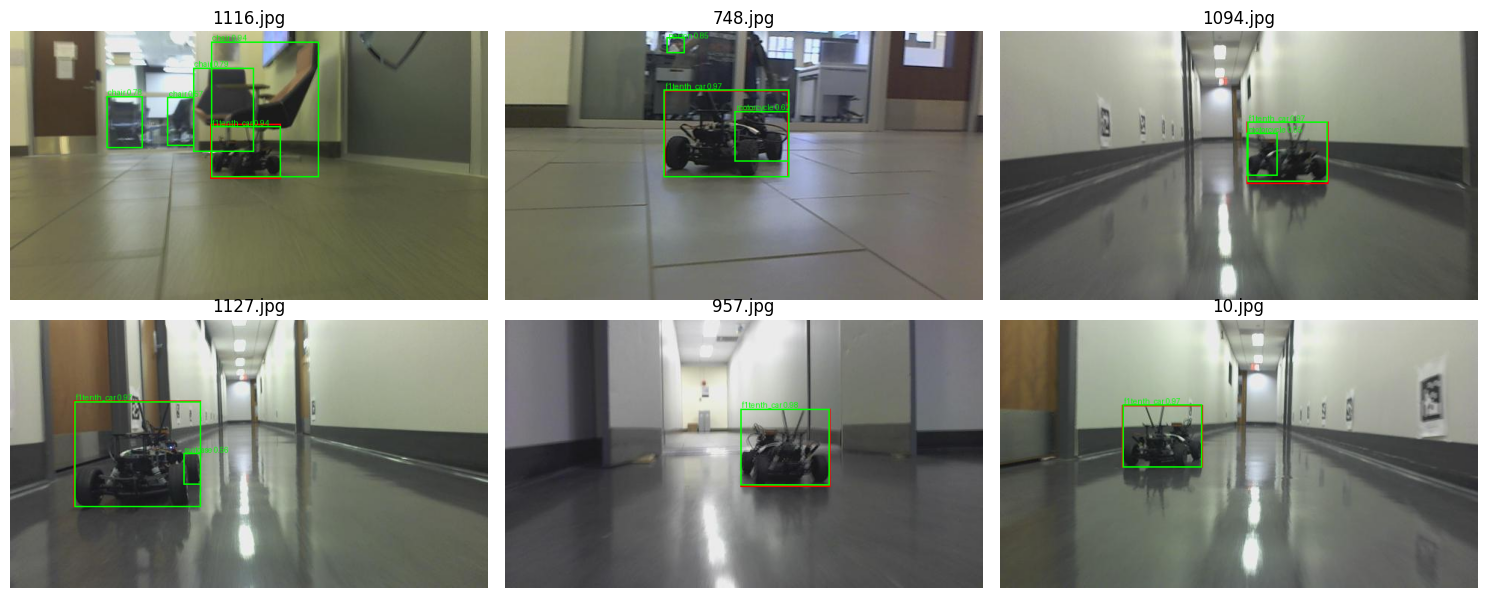

In [ ]:
best_model = load_detector(cfg.out_dir + "/best")
print(evaluate(best_model, val_ds))
print("lab-7 accuracy:", lab_accuracy(best_model, val_ds))
if coco_val_ds is not None:
    print("COCO retention (mAP@50 vs the COCO model):", evaluate(best_model, coco_val_ds)["map_50"])

samples = random.sample(range(len(val_ds)), min(6, len(val_ds)))
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, i in zip(axes.ravel(), samples):
    image, boxes = val_ds.load(i)
    draw_detections(image, detect(best_model, [image], threshold=0.5)[0], ax=ax,
                    title=val_ds.paths[i].name, gt=[xywh_to_xyxy(b) for _, b in boxes])
plt.tight_layout()